# Data Understanding - PlantVillage Dataset

Analyse exploratoire du dataset d'images de maladies des plantes

In [105]:
# Importation des bibliothèques
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

# Configuration pour afficher les images en haute qualité
%matplotlib inline
plt.rcParams['figure.figsize'] = (15, 10)

## 1. Liste des classes et nombre d'images

In [106]:
# Chemin vers le dataset
dataset_path = 'PlantVillage'

# Lister toutes les classes (sous-dossiers)
classes = sorted([d for d in os.listdir(dataset_path) 
                  if os.path.isdir(os.path.join(dataset_path, d))])

print(f"Nombre total de classes : {len(classes)}\n")
print("Liste des classes :")
print("-" * 60)
for i, classe in enumerate(classes, 1):
    print(f"{i}. {classe}")

Nombre total de classes : 15

Liste des classes :
------------------------------------------------------------
1. Pepper__bell___Bacterial_spot
2. Pepper__bell___healthy
3. Potato___Early_blight
4. Potato___Late_blight
5. Potato___healthy
6. Tomato_Bacterial_spot
7. Tomato_Early_blight
8. Tomato_Late_blight
9. Tomato_Leaf_Mold
10. Tomato_Septoria_leaf_spot
11. Tomato_Spider_mites_Two_spotted_spider_mite
12. Tomato__Target_Spot
13. Tomato__Tomato_YellowLeaf__Curl_Virus
14. Tomato__Tomato_mosaic_virus
15. Tomato_healthy


In [107]:
# Compter le nombre d'images par classe
class_counts = {}
total_images = 0

for classe in classes:
    class_path = os.path.join(dataset_path, classe)
    # Compter les fichiers images (jpg, jpeg, png)
    images = [f for f in os.listdir(class_path) 
              if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    count = len(images)
    class_counts[classe] = count
    total_images += count

print(f"\nNombre total d'images : {total_images}\n")
print("Répartition des images par classe :")
print("-" * 60)
for classe, count in sorted(class_counts.items(), key=lambda x: x[1], reverse=True):
    percentage = (count / total_images) * 100
    print(f"{classe}: {count} images ({percentage:.2f}%)")


Nombre total d'images : 20638

Répartition des images par classe :
------------------------------------------------------------
Tomato__Tomato_YellowLeaf__Curl_Virus: 3208 images (15.54%)
Tomato_Bacterial_spot: 2127 images (10.31%)
Tomato_Late_blight: 1909 images (9.25%)
Tomato_Septoria_leaf_spot: 1771 images (8.58%)
Tomato_Spider_mites_Two_spotted_spider_mite: 1676 images (8.12%)
Tomato_healthy: 1591 images (7.71%)
Pepper__bell___healthy: 1478 images (7.16%)
Tomato__Target_Spot: 1404 images (6.80%)
Potato___Early_blight: 1000 images (4.85%)
Potato___Late_blight: 1000 images (4.85%)
Tomato_Early_blight: 1000 images (4.85%)
Pepper__bell___Bacterial_spot: 997 images (4.83%)
Tomato_Leaf_Mold: 952 images (4.61%)
Tomato__Tomato_mosaic_virus: 373 images (1.81%)
Potato___healthy: 152 images (0.74%)


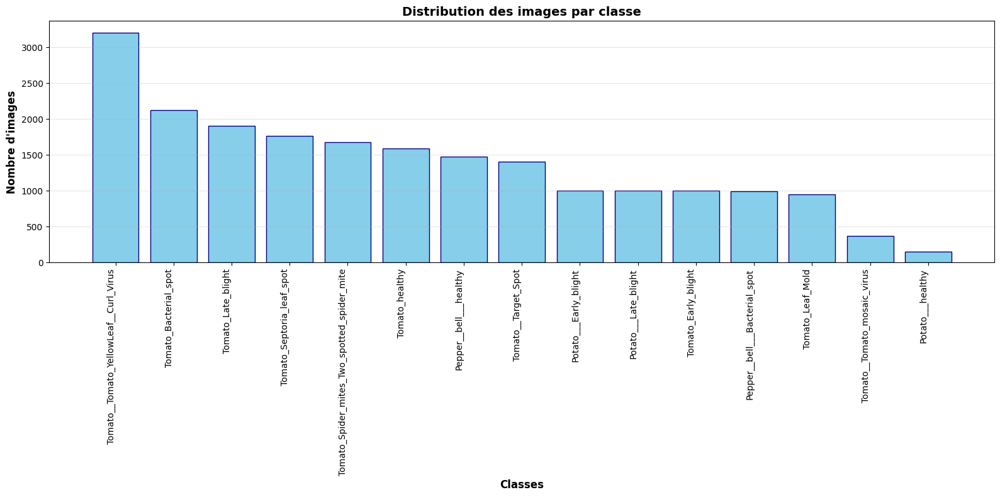


Statistiques :
- Moyenne par classe : 1375.87 images
- Médiane : 1404 images
- Min : 152 images
- Max : 3208 images


In [108]:
# Visualisation de la distribution des images par classe
plt.figure(figsize=(16, 8))
sorted_classes = sorted(class_counts.items(), key=lambda x: x[1], reverse=True)
classes_names = [c[0] for c in sorted_classes]
counts = [c[1] for c in sorted_classes]

plt.bar(range(len(classes_names)), counts, color='skyblue', edgecolor='navy')
plt.xlabel('Classes', fontsize=12, fontweight='bold')
plt.ylabel('Nombre d\'images', fontsize=12, fontweight='bold')
plt.title('Distribution des images par classe', fontsize=14, fontweight='bold')
plt.xticks(range(len(classes_names)), classes_names, rotation=90, ha='right')
plt.tight_layout()
plt.grid(axis='y', alpha=0.3)
plt.show()

# Statistiques descriptives
print(f"\nStatistiques :")
print(f"- Moyenne par classe : {np.mean(counts):.2f} images")
print(f"- Médiane : {np.median(counts):.0f} images")
print(f"- Min : {np.min(counts)} images")
print(f"- Max : {np.max(counts)} images")

## 2. Visualisation d'échantillons d'images

In [109]:
# Fonction pour afficher des images aléatoires d'une classe
def display_sample_images(classe, num_samples=5):
    """Affiche num_samples images aléatoires d'une classe donnée"""
    class_path = os.path.join(dataset_path, classe)
    images = [f for f in os.listdir(class_path) 
              if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    
    # Vérifier s'il y a des images
    if len(images) == 0:
        print(f"⚠️ Aucune image trouvée dans la classe '{classe}'")
        return
    
    # Sélectionner des images aléatoires
    num_to_show = min(num_samples, len(images))
    sample_images = np.random.choice(images, num_to_show, replace=False)
    
    fig, axes = plt.subplots(1, num_to_show, figsize=(15, 3))
    if num_to_show == 1:
        axes = [axes]
    
    for idx, img_name in enumerate(sample_images):
        img_path = os.path.join(class_path, img_name)
        # Lire l'image avec OpenCV (BGR)
        img = cv2.imread(img_path)
        
        if img is None:
            axes[idx].text(0.5, 0.5, 'Image corrompue', ha='center', va='center')
            axes[idx].axis('off')
        else:
            # Convertir BGR vers RGB pour matplotlib
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[idx].imshow(img_rgb)
            axes[idx].axis('off')
            axes[idx].set_title(f"{img.shape[1]}x{img.shape[0]}", fontsize=9)
    
    plt.suptitle(f"Classe: {classe}", fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

Affichage de 5 images pour chaque classe...



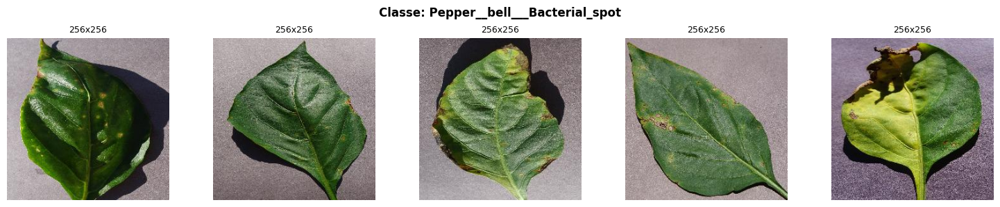

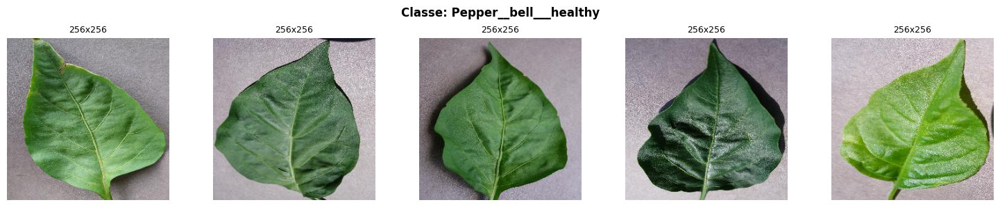

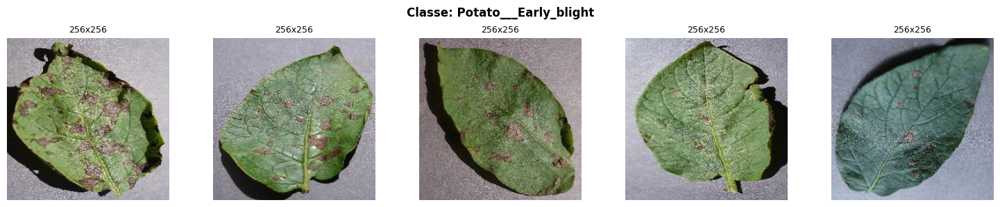

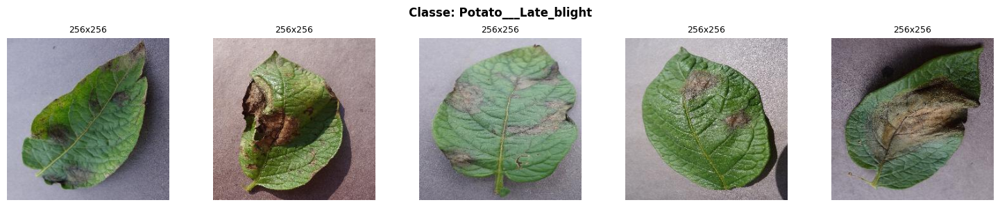

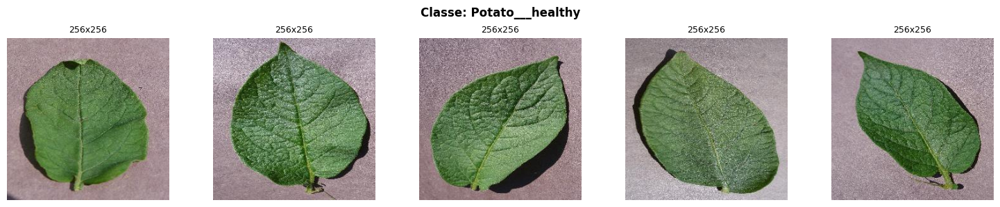

...

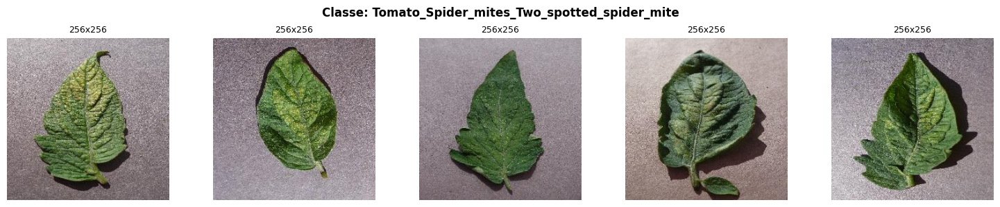

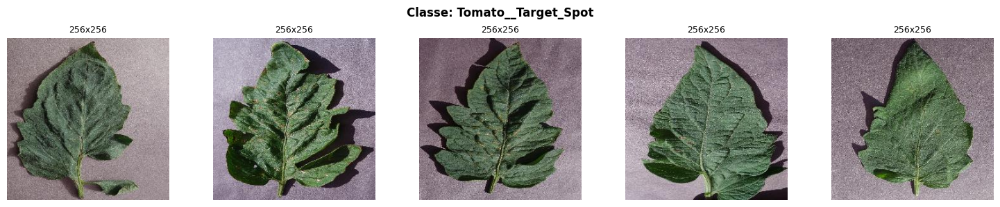

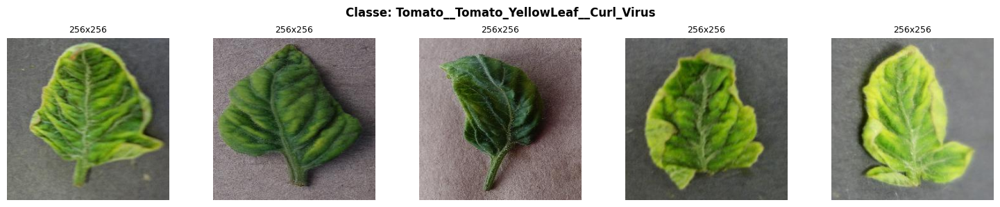

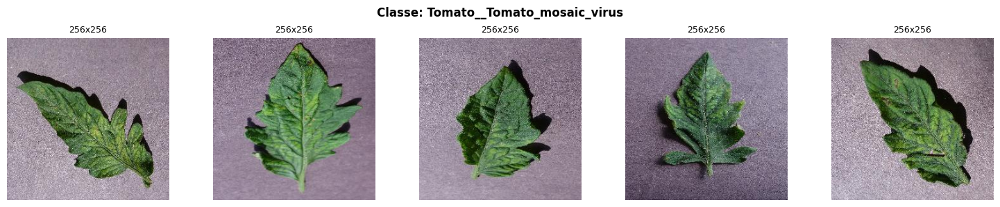

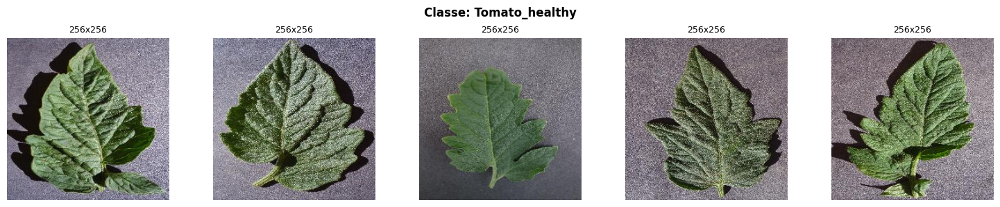

In [110]:
# Afficher 5 images pour chaque classe
print("Affichage de 5 images pour chaque classe...\n")
for classe in classes:
    display_sample_images(classe, num_samples=5)

## 3. Analyse des dimensions et formats

In [111]:
# Analyse des dimensions et formats des images
image_dimensions = []
image_formats = []
image_channels = []

print("Analyse des images en cours...\n")

for classe in classes:
    class_path = os.path.join(dataset_path, classe)
    images = [f for f in os.listdir(class_path) 
              if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    
    # Échantillonner quelques images par classe pour l'analyse
    sample_size = min(50, len(images))  # Analyser 50 images par classe max
    sample_images = np.random.choice(images, sample_size, replace=False)
    
    for img_name in sample_images:
        img_path = os.path.join(class_path, img_name)
        img = cv2.imread(img_path)
        
        if img is not None:
            height, width, channels = img.shape
            image_dimensions.append((width, height))
            image_channels.append(channels)
            
            # Déterminer le format
            ext = os.path.splitext(img_name)[1].lower()
            image_formats.append(ext)

print(f"Nombre d'images analysées : {len(image_dimensions)}")

Analyse des images en cours...

Nombre d'images analysées : 750


In [112]:
# Statistiques sur les formats
format_counts = Counter(image_formats)
print("\nRépartition des formats d'images :")
print("-" * 40)
for fmt, count in format_counts.items():
    percentage = (count / len(image_formats)) * 100
    print(f"{fmt}: {count} images ({percentage:.2f}%)")

# Statistiques sur les canaux
channel_counts = Counter(image_channels)
print("\nNombre de canaux :")
print("-" * 40)
for channels, count in channel_counts.items():
    channel_type = "RGB" if channels == 3 else "Niveaux de gris" if channels == 1 else f"{channels} canaux"
    percentage = (count / len(image_channels)) * 100
    print(f"{channel_type}: {count} images ({percentage:.2f}%)")


Répartition des formats d'images :
----------------------------------------
.jpg: 750 images (100.00%)

Nombre de canaux :
----------------------------------------
RGB: 750 images (100.00%)


In [113]:
# Statistiques sur les dimensions
widths = [dim[0] for dim in image_dimensions]
heights = [dim[1] for dim in image_dimensions]

print("\nStatistiques des dimensions :")
print("-" * 40)
print(f"Largeur - Min: {min(widths)}px, Max: {max(widths)}px, Moyenne: {np.mean(widths):.2f}px")
print(f"Hauteur - Min: {min(heights)}px, Max: {max(heights)}px, Moyenne: {np.mean(heights):.2f}px")

# Vérifier si toutes les images ont la même dimension
unique_dimensions = set(image_dimensions)
print(f"\nNombre de dimensions uniques : {len(unique_dimensions)}")
if len(unique_dimensions) <= 10:
    print("\nDimensions trouvées :")
    dim_counts = Counter(image_dimensions)
    for dim, count in sorted(dim_counts.items(), key=lambda x: x[1], reverse=True):
        percentage = (count / len(image_dimensions)) * 100
        print(f"  {dim[0]}x{dim[1]}: {count} images ({percentage:.2f}%)")


Statistiques des dimensions :
----------------------------------------
Largeur - Min: 256px, Max: 256px, Moyenne: 256.00px
Hauteur - Min: 256px, Max: 256px, Moyenne: 256.00px

Nombre de dimensions uniques : 1

Dimensions trouvées :
  256x256: 750 images (100.00%)


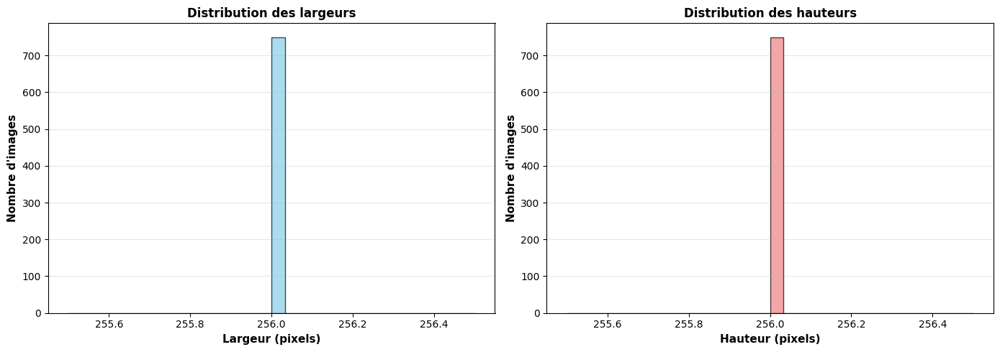

In [114]:
# Visualisation de la distribution des dimensions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogramme des largeurs
axes[0].hist(widths, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Largeur (pixels)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Nombre d\'images', fontsize=11, fontweight='bold')
axes[0].set_title('Distribution des largeurs', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

# Histogramme des hauteurs
axes[1].hist(heights, bins=30, color='lightcoral', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Hauteur (pixels)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Nombre d\'images', fontsize=11, fontweight='bold')
axes[1].set_title('Distribution des hauteurs', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Résumé de l'analyse

In [115]:
# Résumé global du dataset
print("=" * 60)
print("RÉSUMÉ DE L'ANALYSE DU DATASET PLANTVILLAGE")
print("=" * 60)
print(f"\n📊 Classes : {len(classes)} différentes maladies")
print(f"📷 Images totales : {total_images}")
print(f"📈 Moyenne par classe : {total_images / len(classes):.0f} images")
print(f"\n📐 Dimensions des images :")
print(f"   - Largeur : {min(widths)}px à {max(widths)}px (moyenne : {np.mean(widths):.0f}px)")
print(f"   - Hauteur : {min(heights)}px à {max(heights)}px (moyenne : {np.mean(heights):.0f}px)")
print(f"\n🎨 Formats principaux : {', '.join([fmt for fmt in format_counts.keys()])}")
print(f"🌈 Canaux : {'RGB (3 canaux)' if 3 in channel_counts else 'Mixte'}")
print("\n" + "=" * 60)

RÉSUMÉ DE L'ANALYSE DU DATASET PLANTVILLAGE

📊 Classes : 15 différentes maladies
📷 Images totales : 20638
📈 Moyenne par classe : 1376 images

📐 Dimensions des images :
   - Largeur : 256px à 256px (moyenne : 256px)
   - Hauteur : 256px à 256px (moyenne : 256px)

🎨 Formats principaux : .jpg
🌈 Canaux : RGB (3 canaux)



# Data Cleaning / Préprocessing

Nettoyage et vérification de la qualité du dataset

In [116]:
# Importations supplémentaires pour le nettoyage
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

## 1. Vérification des dossiers vides

In [117]:
# Vérifier les dossiers vides ou avec peu d'images
empty_folders = []
low_image_folders = []
threshold_min = 10  # Seuil minimal d'images par classe

print("Vérification des dossiers...\n")

for classe in classes:
    class_path = os.path.join(dataset_path, classe)
    images = [f for f in os.listdir(class_path) 
              if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    
    if len(images) == 0:
        empty_folders.append(classe)
    elif len(images) < threshold_min:
        low_image_folders.append((classe, len(images)))

print(f"📁 Dossiers complètement vides : {len(empty_folders)}")
if empty_folders:
    for folder in empty_folders:
        print(f"   - {folder}")
else:
    print("   ✓ Aucun dossier vide")

print(f"\n⚠️ Dossiers avec moins de {threshold_min} images : {len(low_image_folders)}")
if low_image_folders:
    for folder, count in low_image_folders:
        print(f"   - {folder}: {count} images")
else:
    print(f"   ✓ Tous les dossiers ont au moins {threshold_min} images")

Vérification des dossiers...

📁 Dossiers complètement vides : 0
   ✓ Aucun dossier vide

⚠️ Dossiers avec moins de 10 images : 0
   ✓ Tous les dossiers ont au moins 10 images


## 2. Vérification des images corrompues

In [118]:
# Vérifier les images corrompues ou illisibles
corrupted_images = []
unreadable_images = []

print("Vérification des images corrompues...\n")
print("(Cela peut prendre quelques minutes)\n")

for classe in classes:
    class_path = os.path.join(dataset_path, classe)
    images = [f for f in os.listdir(class_path) 
              if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    
    for img_name in images:
        img_path = os.path.join(class_path, img_name)
        
        # Test 1: Vérifier avec OpenCV
        try:
            img_cv = cv2.imread(img_path)
            if img_cv is None:
                corrupted_images.append((classe, img_name, "OpenCV ne peut pas lire"))
                continue
        except Exception as e:
            corrupted_images.append((classe, img_name, f"OpenCV erreur: {str(e)}"))
            continue
        
        # Test 2: Vérifier avec PIL
        try:
            img_pil = Image.open(img_path)
            img_pil.verify()  # Vérifier l'intégrité
        except Exception as e:
            corrupted_images.append((classe, img_name, f"PIL erreur: {str(e)}"))
            continue

print(f"🔍 Images analysées : {sum([len([f for f in os.listdir(os.path.join(dataset_path, c)) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]) for c in classes])}")
print(f"❌ Images corrompues trouvées : {len(corrupted_images)}\n")

if corrupted_images:
    print("Liste des images corrompues :")
    print("-" * 80)
    for classe, img_name, reason in corrupted_images[:20]:  # Afficher les 20 premières
        print(f"   - {classe}/{img_name}")
        print(f"     Raison: {reason}")
    if len(corrupted_images) > 20:
        print(f"\n   ... et {len(corrupted_images) - 20} autres images corrompues")
else:
    print("✓ Aucune image corrompue détectée")

Vérification des images corrompues...

(Cela peut prendre quelques minutes)

🔍 Images analysées : 20638
❌ Images corrompues trouvées : 0

✓ Aucune image corrompue détectée


## 3. Vérification des formats d'images

In [119]:
# Vérifier les formats d'images en détail
format_details = {}
unsupported_formats = []

print("Analyse des formats d'images...\n")

for classe in classes:
    class_path = os.path.join(dataset_path, classe)
    all_files = os.listdir(class_path)
    
    for file_name in all_files:
        file_path = os.path.join(class_path, file_name)
        
        # Ignorer les dossiers
        if os.path.isdir(file_path):
            continue
        
        ext = os.path.splitext(file_name)[1].lower()
        
        # Vérifier si c'est un format supporté
        if ext not in ['.jpg', '.jpeg', '.png']:
            unsupported_formats.append((classe, file_name, ext))
        else:
            format_details[ext] = format_details.get(ext, 0) + 1

print("Formats d'images trouvés :")
print("-" * 50)
for fmt, count in sorted(format_details.items()):
    print(f"   {fmt}: {count} images")

print(f"\n⚠️ Fichiers avec formats non supportés : {len(unsupported_formats)}")
if unsupported_formats:
    print("\nExemples de fichiers non supportés :")
    for classe, file_name, ext in unsupported_formats[:10]:
        print(f"   - {classe}/{file_name} (format: {ext})")
    if len(unsupported_formats) > 10:
        print(f"\n   ... et {len(unsupported_formats) - 10} autres fichiers")
else:
    print("   ✓ Tous les fichiers sont dans des formats supportés (JPG/JPEG/PNG)")

Analyse des formats d'images...

Formats d'images trouvés :
--------------------------------------------------
   .jpeg: 1 images
   .jpg: 20636 images
   .png: 1 images

⚠️ Fichiers avec formats non supportés : 1

Exemples de fichiers non supportés :
   - Tomato__Tomato_YellowLeaf__Curl_Virus/svn-r6Yb5c (format: )


## 4. Vérification des dimensions et canaux

In [120]:
# Vérifier dimensions et canaux en détail
dimension_issues = []
channel_issues = []
too_small_images = []
too_large_images = []

MIN_SIZE = 50  # Taille minimale acceptable en pixels
MAX_SIZE = 10000  # Taille maximale acceptable en pixels

print("Vérification des dimensions et canaux...\n")

for classe in classes:
    class_path = os.path.join(dataset_path, classe)
    images = [f for f in os.listdir(class_path) 
              if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    
    for img_name in images:
        img_path = os.path.join(class_path, img_name)
        
        try:
            img = cv2.imread(img_path)
            
            if img is not None:
                height, width, channels = img.shape
                
                # Vérifier les canaux (doit être 3 pour RGB)
                if channels != 3:
                    channel_issues.append((classe, img_name, channels))
                
                # Vérifier les dimensions trop petites
                if width < MIN_SIZE or height < MIN_SIZE:
                    too_small_images.append((classe, img_name, width, height))
                
                # Vérifier les dimensions trop grandes
                if width > MAX_SIZE or height > MAX_SIZE:
                    too_large_images.append((classe, img_name, width, height))
        except Exception as e:
            dimension_issues.append((classe, img_name, str(e)))

print(f"⚠️ Images avec problèmes de canaux (non-RGB) : {len(channel_issues)}")
if channel_issues:
    print("   Exemples :")
    for classe, img_name, channels in channel_issues[:5]:
        print(f"   - {classe}/{img_name} ({channels} canaux)")
    if len(channel_issues) > 5:
        print(f"   ... et {len(channel_issues) - 5} autres")
else:
    print("   ✓ Toutes les images sont en RGB (3 canaux)")

print(f"\n⚠️ Images trop petites (< {MIN_SIZE}px) : {len(too_small_images)}")
if too_small_images:
    print("   Exemples :")
    for classe, img_name, width, height in too_small_images[:5]:
        print(f"   - {classe}/{img_name} ({width}x{height}px)")
    if len(too_small_images) > 5:
        print(f"   ... et {len(too_small_images) - 5} autres")
else:
    print(f"   ✓ Toutes les images ont au moins {MIN_SIZE}px")

print(f"\n⚠️ Images trop grandes (> {MAX_SIZE}px) : {len(too_large_images)}")
if too_large_images:
    print("   Exemples :")
    for classe, img_name, width, height in too_large_images[:5]:
        print(f"   - {classe}/{img_name} ({width}x{height}px)")
    if len(too_large_images) > 5:
        print(f"   ... et {len(too_large_images) - 5} autres")
else:
    print(f"   ✓ Aucune image ne dépasse {MAX_SIZE}px")

Vérification des dimensions et canaux...

⚠️ Images avec problèmes de canaux (non-RGB) : 0
   ✓ Toutes les images sont en RGB (3 canaux)

⚠️ Images trop petites (< 50px) : 0
   ✓ Toutes les images ont au moins 50px

⚠️ Images trop grandes (> 10000px) : 0
   ✓ Aucune image ne dépasse 10000px


## 5. Identification des images à exclure

In [121]:
# Créer une liste consolidée des images à exclure
images_to_exclude = set()

# Ajouter les images corrompues
for classe, img_name, _ in corrupted_images:
    images_to_exclude.add(f"{classe}/{img_name}")

# Ajouter les images avec problèmes de canaux
for classe, img_name, _ in channel_issues:
    images_to_exclude.add(f"{classe}/{img_name}")

# Ajouter les images trop petites
for classe, img_name, _, _ in too_small_images:
    images_to_exclude.add(f"{classe}/{img_name}")

# Ajouter les images trop grandes
for classe, img_name, _, _ in too_large_images:
    images_to_exclude.add(f"{classe}/{img_name}")

print("=" * 60)
print("IMAGES À EXCLURE DU DATASET")
print("=" * 60)
print(f"\nNombre total d'images problématiques : {len(images_to_exclude)}")
print(f"\nDétails :")
print(f"   - Images corrompues : {len(corrupted_images)}")
print(f"   - Images avec mauvais canaux : {len(channel_issues)}")
print(f"   - Images trop petites : {len(too_small_images)}")
print(f"   - Images trop grandes : {len(too_large_images)}")
print("\n" + "=" * 60)

# Sauvegarder la liste dans un fichier
if len(images_to_exclude) > 0:
    with open('images_to_exclude.txt', 'w', encoding='utf-8') as f:
        for img_path in sorted(images_to_exclude):
            f.write(f"{img_path}\n")
    print(f"\n✓ Liste sauvegardée dans 'images_to_exclude.txt'")
else:
    print("\n✓ Aucune image à exclure - Dataset propre !")

IMAGES À EXCLURE DU DATASET

Nombre total d'images problématiques : 0

Détails :
   - Images corrompues : 0
   - Images avec mauvais canaux : 0
   - Images trop petites : 0
   - Images trop grandes : 0


✓ Aucune image à exclure - Dataset propre !


## 6. Résumé final - Images valides par classe

In [122]:
# Calculer le nombre d'images valides par classe
valid_class_counts = {}
total_valid_images = 0
total_excluded_images = 0

for classe in classes:
    class_path = os.path.join(dataset_path, classe)
    all_images = [f for f in os.listdir(class_path) 
                  if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    
    # Filtrer les images valides
    valid_images = [img for img in all_images 
                    if f"{classe}/{img}" not in images_to_exclude]
    
    valid_class_counts[classe] = len(valid_images)
    total_valid_images += len(valid_images)
    total_excluded_images += (len(all_images) - len(valid_images))

print("=" * 80)
print("RÉSUMÉ FINAL - DATASET NETTOYÉ")
print("=" * 80)
print(f"\n📊 Statistiques globales :")
print(f"   - Images totales avant nettoyage : {total_images}")
print(f"   - Images exclues : {total_excluded_images}")
print(f"   - Images valides : {total_valid_images}")
print(f"   - Taux de validité : {(total_valid_images / total_images * 100):.2f}%")

print(f"\n📁 Nombre de classes : {len(classes)}")
print(f"   - Moyenne d'images valides par classe : {total_valid_images / len(classes):.1f}")

print(f"\n📋 Répartition des images valides par classe :")
print("-" * 80)
for classe, count in sorted(valid_class_counts.items(), key=lambda x: x[1], reverse=True):
    original_count = class_counts[classe]
    excluded = original_count - count
    status = "✓" if excluded == 0 else f"⚠️ (-{excluded})"
    print(f"{status} {classe}: {count} images valides")

print("\n" + "=" * 80)

RÉSUMÉ FINAL - DATASET NETTOYÉ

📊 Statistiques globales :
   - Images totales avant nettoyage : 20638
   - Images exclues : 0
   - Images valides : 20638
   - Taux de validité : 100.00%

📁 Nombre de classes : 15
   - Moyenne d'images valides par classe : 1375.9

📋 Répartition des images valides par classe :
--------------------------------------------------------------------------------
✓ Tomato__Tomato_YellowLeaf__Curl_Virus: 3208 images valides
✓ Tomato_Bacterial_spot: 2127 images valides
✓ Tomato_Late_blight: 1909 images valides
✓ Tomato_Septoria_leaf_spot: 1771 images valides
✓ Tomato_Spider_mites_Two_spotted_spider_mite: 1676 images valides
✓ Tomato_healthy: 1591 images valides
✓ Pepper__bell___healthy: 1478 images valides
✓ Tomato__Target_Spot: 1404 images valides
✓ Potato___Early_blight: 1000 images valides
✓ Potato___Late_blight: 1000 images valides
✓ Tomato_Early_blight: 1000 images valides
✓ Pepper__bell___Bacterial_spot: 997 images valides
✓ Tomato_Leaf_Mold: 952 images vali

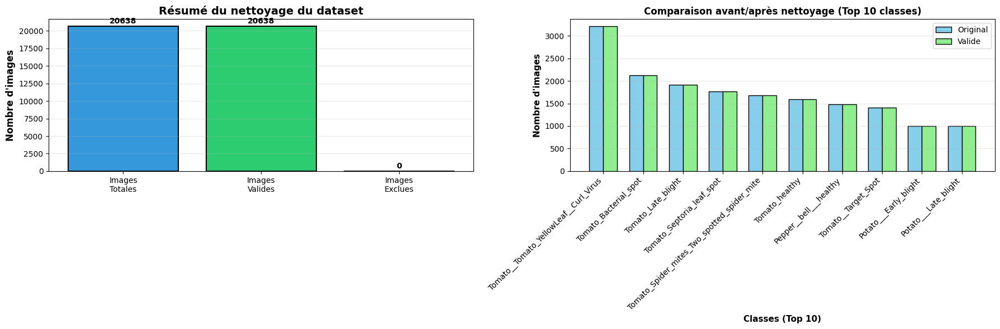


✅ NETTOYAGE TERMINÉ

Le dataset est prêt pour l'entraînement avec 20638 images valides.



In [123]:
# Visualisation : Avant et Après nettoyage
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Graphique 1: Comparaison globale
categories = ['Images\nTotales', 'Images\nValides', 'Images\nExclues']
values = [total_images, total_valid_images, total_excluded_images]
colors = ['#3498db', '#2ecc71', '#e74c3c']

ax1.bar(categories, values, color=colors, edgecolor='black', linewidth=1.5)
ax1.set_ylabel('Nombre d\'images', fontsize=12, fontweight='bold')
ax1.set_title('Résumé du nettoyage du dataset', fontsize=14, fontweight='bold')
ax1.grid(axis='y', alpha=0.3)

# Ajouter les valeurs sur les barres
for i, v in enumerate(values):
    ax1.text(i, v + max(values) * 0.02, str(v), ha='center', fontweight='bold')

# Graphique 2: Comparaison par classe (top 10)
top_classes = sorted(class_counts.items(), key=lambda x: x[1], reverse=True)[:10]
class_names = [c[0] for c in top_classes]
original_counts = [class_counts[c] for c in class_names]
valid_counts = [valid_class_counts[c] for c in class_names]

x = np.arange(len(class_names))
width = 0.35

bars1 = ax2.bar(x - width/2, original_counts, width, label='Original', 
                color='skyblue', edgecolor='black')
bars2 = ax2.bar(x + width/2, valid_counts, width, label='Valide', 
                color='lightgreen', edgecolor='black')

ax2.set_xlabel('Classes (Top 10)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Nombre d\'images', fontsize=11, fontweight='bold')
ax2.set_title('Comparaison avant/après nettoyage (Top 10 classes)', fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(class_names, rotation=45, ha='right')
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Résumé textuel final
print("\n" + "=" * 80)
print("✅ NETTOYAGE TERMINÉ")
print("=" * 80)
print(f"\nLe dataset est prêt pour l'entraînement avec {total_valid_images} images valides.")
if total_excluded_images > 0:
    print(f"Consultez 'images_to_exclude.txt' pour la liste complète des images exclues.")
print("\n" + "=" * 80)

# Data Preprocessing pour Deep Learning

Préparation des données pour l'entraînement avec TensorFlow

In [124]:
# Importations pour TensorFlow et preprocessing
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import shutil
from pathlib import Path

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU disponible: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.20.0
GPU disponible: []


## 1. Configuration et paramètres

In [125]:
# Paramètres de preprocessing
IMG_SIZE = 256  # Taille cible des images
BATCH_SIZE = 32
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# Paramètres de data augmentation pour les classes rares
AUGMENTATION_FACTOR = 3  # Multiplier par 3 les images des classes rares
RARE_CLASS_THRESHOLD = np.median([valid_class_counts[c] for c in classes])  # Seuil: médiane

print("=" * 60)
print("CONFIGURATION DU PREPROCESSING")
print("=" * 60)
print(f"\n📐 Taille des images : {IMG_SIZE}x{IMG_SIZE} pixels")
print(f"📦 Taille des batches : {BATCH_SIZE}")
print(f"\n📊 Split du dataset :")
print(f"   - Train : {TRAIN_RATIO*100:.0f}%")
print(f"   - Validation : {VAL_RATIO*100:.0f}%")
print(f"   - Test : {TEST_RATIO*100:.0f}%")
print(f"\n🔄 Data Augmentation :")
print(f"   - Seuil classe rare : {RARE_CLASS_THRESHOLD:.0f} images")
print(f"   - Facteur d'augmentation : x{AUGMENTATION_FACTOR}")
print("\n" + "=" * 60)

CONFIGURATION DU PREPROCESSING

📐 Taille des images : 256x256 pixels
📦 Taille des batches : 32

📊 Split du dataset :
   - Train : 70%
   - Validation : 15%
   - Test : 15%

🔄 Data Augmentation :
   - Seuil classe rare : 1404 images
   - Facteur d'augmentation : x3



## 2. Création de la structure Train/Val/Test

In [126]:
# Créer la structure de dossiers pour le dataset splitté
output_dir = Path('dataset_preprocessed')

# Supprimer le dossier s'il existe déjà
if output_dir.exists():
    shutil.rmtree(output_dir)
    print("🗑️ Ancien dossier supprimé\n")

# Créer les dossiers train/val/test
for split in ['train', 'val', 'test']:
    for classe in classes:
        Path(output_dir / split / classe).mkdir(parents=True, exist_ok=True)

print("✓ Structure de dossiers créée :")
print(f"   - {output_dir}/train/")
print(f"   - {output_dir}/val/")
print(f"   - {output_dir}/test/")
print(f"\nChaque split contient {len(classes)} sous-dossiers (classes)")

🗑️ Ancien dossier supprimé

✓ Structure de dossiers créée :
   - dataset_preprocessed/train/
   - dataset_preprocessed/val/
   - dataset_preprocessed/test/

Chaque split contient 15 sous-dossiers (classes)


In [127]:
# Splitter et copier les images valides
np.random.seed(42)  # Pour la reproductibilité

split_counts = {'train': {}, 'val': {}, 'test': {}}

print("Copie des images dans les dossiers train/val/test...\n")

for classe in classes:
    # Récupérer toutes les images valides de cette classe
    class_path = os.path.join(dataset_path, classe)
    all_imgs = [f for f in os.listdir(class_path) 
                if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    
    # Filtrer les images valides (non exclues)
    valid_imgs = [img for img in all_imgs 
                  if f"{classe}/{img}" not in images_to_exclude]
    
    # Mélanger aléatoirement
    np.random.shuffle(valid_imgs)
    
    # Calculer les indices de split
    n_total = len(valid_imgs)
    n_train = int(n_total * TRAIN_RATIO)
    n_val = int(n_total * VAL_RATIO)
    
    # Splitter
    train_imgs = valid_imgs[:n_train]
    val_imgs = valid_imgs[n_train:n_train + n_val]
    test_imgs = valid_imgs[n_train + n_val:]
    
    # Copier les images
    for img_name in train_imgs:
        src = os.path.join(class_path, img_name)
        dst = output_dir / 'train' / classe / img_name
        shutil.copy2(src, dst)
    
    for img_name in val_imgs:
        src = os.path.join(class_path, img_name)
        dst = output_dir / 'val' / classe / img_name
        shutil.copy2(src, dst)
    
    for img_name in test_imgs:
        src = os.path.join(class_path, img_name)
        dst = output_dir / 'test' / classe / img_name
        shutil.copy2(src, dst)
    
    # Enregistrer les comptes
    split_counts['train'][classe] = len(train_imgs)
    split_counts['val'][classe] = len(val_imgs)
    split_counts['test'][classe] = len(test_imgs)

print("✓ Images copiées avec succès !")

Copie des images dans les dossiers train/val/test...

✓ Images copiées avec succès !


In [128]:
# Statistiques du split
total_train = sum(split_counts['train'].values())
total_val = sum(split_counts['val'].values())
total_test = sum(split_counts['test'].values())
total_all = total_train + total_val + total_test

print("=" * 60)
print("STATISTIQUES DU SPLIT")
print("=" * 60)
print(f"\n📊 Répartition globale :")
print(f"   - Train : {total_train} images ({total_train/total_all*100:.1f}%)")
print(f"   - Validation : {total_val} images ({total_val/total_all*100:.1f}%)")
print(f"   - Test : {total_test} images ({total_test/total_all*100:.1f}%)")
print(f"   - Total : {total_all} images")

print(f"\n📋 Répartition par classe (5 premières) :")
print("-" * 60)
for i, classe in enumerate(classes[:5]):
    print(f"{classe}:")
    print(f"   Train: {split_counts['train'][classe]:4d} | Val: {split_counts['val'][classe]:3d} | Test: {split_counts['test'][classe]:3d}")
if len(classes) > 5:
    print(f"\n... et {len(classes) - 5} autres classes")
print("\n" + "=" * 60)

STATISTIQUES DU SPLIT

📊 Répartition globale :
   - Train : 14440 images (70.0%)
   - Validation : 3089 images (15.0%)
   - Test : 3109 images (15.1%)
   - Total : 20638 images

📋 Répartition par classe (5 premières) :
------------------------------------------------------------
Pepper__bell___Bacterial_spot:
   Train:  697 | Val: 149 | Test: 151
Pepper__bell___healthy:
   Train: 1034 | Val: 221 | Test: 223
Potato___Early_blight:
   Train:  700 | Val: 150 | Test: 150
Potato___Late_blight:
   Train:  700 | Val: 150 | Test: 150
Potato___healthy:
   Train:  106 | Val:  22 | Test:  24

... et 10 autres classes



## 3. Data Augmentation pour classes rares

In [129]:
# Identifier les classes rares dans le train set
rare_classes = [classe for classe in classes 
                if split_counts['train'][classe] < RARE_CLASS_THRESHOLD]

print(f"Classes rares identifiées (< {RARE_CLASS_THRESHOLD:.0f} images) : {len(rare_classes)}")
print("\nListe des classes à augmenter :")
print("-" * 60)
for classe in rare_classes[:10]:
    print(f"   - {classe}: {split_counts['train'][classe]} images")
if len(rare_classes) > 10:
    print(f"\n... et {len(rare_classes) - 10} autres classes")

Classes rares identifiées (< 1404 images) : 13

Liste des classes à augmenter :
------------------------------------------------------------
   - Pepper__bell___Bacterial_spot: 697 images
   - Pepper__bell___healthy: 1034 images
   - Potato___Early_blight: 700 images
   - Potato___Late_blight: 700 images
   - Potato___healthy: 106 images
   - Tomato_Early_blight: 700 images
   - Tomato_Late_blight: 1336 images
   - Tomato_Leaf_Mold: 666 images
   - Tomato_Septoria_leaf_spot: 1239 images
   - Tomato_Spider_mites_Two_spotted_spider_mite: 1173 images

... et 3 autres classes


In [130]:
# Configurer l'augmenteur d'images
datagen = ImageDataGenerator(
    rotation_range=30,          # Rotation jusqu'à 30 degrés
    width_shift_range=0.2,      # Décalage horizontal
    height_shift_range=0.2,     # Décalage vertical
    shear_range=0.2,            # Distorsion
    zoom_range=0.2,             # Zoom in/out
    horizontal_flip=True,        # Flip horizontal
    brightness_range=[0.7, 1.3], # Variation de luminosité
    fill_mode='nearest'
)

print("Configuration de Data Augmentation :")
print("   - Rotation : ±30°")
print("   - Décalage : ±20%")
print("   - Zoom : ±20%")
print("   - Flip horizontal : Oui")
print("   - Luminosité : 70%-130%")

Configuration de Data Augmentation :
   - Rotation : ±30°
   - Décalage : ±20%
   - Zoom : ±20%
   - Flip horizontal : Oui
   - Luminosité : 70%-130%


In [131]:
# Appliquer l'augmentation aux classes rares
augmented_count = 0

print("\nAugmentation des classes rares en cours...\n")

for classe in rare_classes:
    class_train_path = output_dir / 'train' / classe
    images = list(class_train_path.glob('*.jp*g')) + list(class_train_path.glob('*.png'))
    
    current_count = len(images)
    target_count = int(RARE_CLASS_THRESHOLD * AUGMENTATION_FACTOR)
    images_to_generate = target_count - current_count
    
    if images_to_generate > 0:
        # Générer des images augmentées
        for i, img_path in enumerate(images):
            # Lire l'image
            img = keras.preprocessing.image.load_img(img_path)
            img_array = keras.preprocessing.image.img_to_array(img)
            img_array = np.expand_dims(img_array, axis=0)
            
            # Générer des variations
            num_variations = min(AUGMENTATION_FACTOR, images_to_generate // len(images) + 1)
            
            gen = datagen.flow(img_array, batch_size=1)
            for j in range(num_variations):
                if augmented_count >= images_to_generate:
                    break
                    
                aug_img = next(gen)[0].astype('uint8')
                aug_img_pil = Image.fromarray(aug_img)
                
                # Sauvegarder l'image augmentée
                base_name = img_path.stem
                ext = img_path.suffix
                aug_img_pil.save(class_train_path / f"{base_name}_aug_{j}{ext}")
                augmented_count += 1
            
            if augmented_count >= images_to_generate:
                break

print(f"✓ {augmented_count} images augmentées générées pour les classes rares")


Augmentation des classes rares en cours...

✓ 3951 images augmentées générées pour les classes rares


## 4. Création des datasets TensorFlow avec normalisation

In [132]:
# Fonction de preprocessing : redimensionnement + normalisation
def preprocess_image(image, label):
    """Redimensionne et normalise les images"""
    # Redimensionner à 256x256
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    # Normaliser entre 0 et 1
    image = image / 255.0
    return image, label

print("Fonction de preprocessing créée :")
print(f"   - Redimensionnement : {IMG_SIZE}x{IMG_SIZE}px")
print(f"   - Normalisation : valeurs [0, 1]")

Fonction de preprocessing créée :
   - Redimensionnement : 256x256px
   - Normalisation : valeurs [0, 1]


In [133]:
# Créer les datasets TensorFlow à partir des dossiers
print("\nCréation des datasets TensorFlow...\n")

# Dataset d'entraînement
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    str(output_dir / 'train'),
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True,
    seed=42
)

# Récupérer les noms de classes AVANT d'appliquer les transformations
class_names = train_ds.class_names
print(f"✓ Classes détectées : {len(class_names)}")

# Dataset de validation
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    str(output_dir / 'val'),
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False,
    seed=42
)

# Dataset de test
test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    str(output_dir / 'test'),
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False,
    seed=42
)

# Normaliser les images (valeurs entre 0 et 1)
normalization_layer = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y))

print("✓ Datasets créés avec succès !")


Création des datasets TensorFlow...

Found 18391 files belonging to 15 classes.
✓ Classes détectées : 15
Found 3089 files belonging to 15 classes.
Found 3109 files belonging to 15 classes.
✓ Datasets créés avec succès !


In [134]:
# Optimiser les performances avec prefetching et caching
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

print("✓ Optimisation des performances activée (cache + prefetch)")

✓ Optimisation des performances activée (cache + prefetch)


## 5. Visualisation des données préprocessées

In [135]:
# Afficher les informations sur les classes
print(f"Nombre de classes : {len(class_names)}\n")
print("Exemples de classes :")
for i, name in enumerate(class_names[:5]):
    print(f"   {i}: {name}")
if len(class_names) > 5:
    print(f"   ... et {len(class_names) - 5} autres")

Nombre de classes : 15

Exemples de classes :
   0: Pepper__bell___Bacterial_spot
   1: Pepper__bell___healthy
   2: Potato___Early_blight
   3: Potato___Late_blight
   4: Potato___healthy
   ... et 10 autres


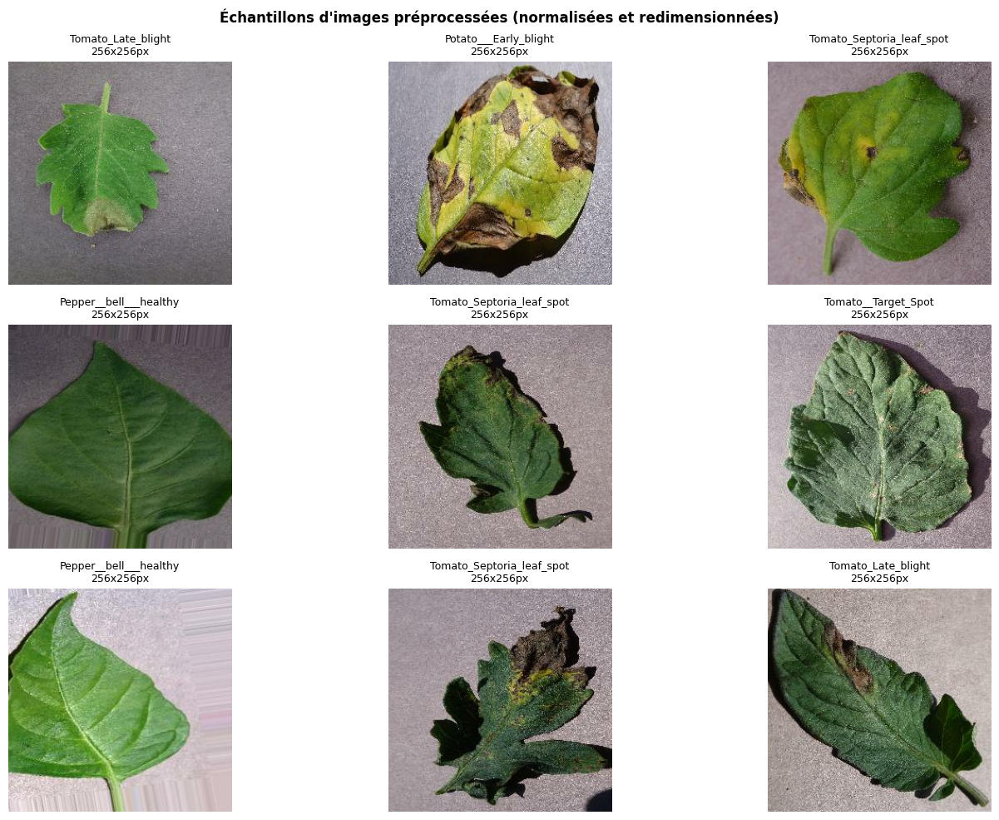


✓ Images redimensionnées à 256x256px
✓ Valeurs normalisées entre 0 et 1
✓ Shape d'un batch : (32, 256, 256, 3)


In [136]:
# Visualiser un batch d'images préprocessées
plt.figure(figsize=(15, 10))

for images, labels in train_ds.take(1):
    for i in range(min(9, images.shape[0])):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        
        # Trouver l'indice de la classe
        class_idx = np.argmax(labels[i])
        plt.title(f"{class_names[class_idx]}\n{IMG_SIZE}x{IMG_SIZE}px", fontsize=9)
        plt.axis('off')

plt.suptitle("Échantillons d'images préprocessées (normalisées et redimensionnées)", 
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n✓ Images redimensionnées à {IMG_SIZE}x{IMG_SIZE}px")
print(f"✓ Valeurs normalisées entre 0 et 1")
print(f"✓ Shape d'un batch : {images.shape}")

## 6. Résumé final du preprocessing

In [137]:
# Calculer les statistiques finales
final_train_count = sum([len(list((output_dir / 'train' / c).glob('*.jp*g'))) + 
                          len(list((output_dir / 'train' / c).glob('*.png'))) 
                          for c in classes])
final_val_count = sum([len(list((output_dir / 'val' / c).glob('*.jp*g'))) + 
                        len(list((output_dir / 'val' / c).glob('*.png'))) 
                        for c in classes])
final_test_count = sum([len(list((output_dir / 'test' / c).glob('*.jp*g'))) + 
                         len(list((output_dir / 'test' / c).glob('*.png'))) 
                         for c in classes])

num_train_batches = tf.data.experimental.cardinality(train_ds).numpy()
num_val_batches = tf.data.experimental.cardinality(val_ds).numpy()
num_test_batches = tf.data.experimental.cardinality(test_ds).numpy()

print("=" * 80)
print("RÉSUMÉ FINAL DU PREPROCESSING")
print("=" * 80)

print("\n📊 DONNÉES :")
print(f"   Train      : {final_train_count:5d} images ({num_train_batches} batches)")
print(f"   Validation : {final_val_count:5d} images ({num_val_batches} batches)")
print(f"   Test       : {final_test_count:5d} images ({num_test_batches} batches)")
print(f"   Total      : {final_train_count + final_val_count + final_test_count:5d} images")

print("\n🔧 TRANSFORMATIONS APPLIQUÉES :")
print(f"   ✓ Redimensionnement : {IMG_SIZE}x{IMG_SIZE} pixels")
print(f"   ✓ Normalisation : valeurs [0, 1]")
print(f"   ✓ Data Augmentation : {len(rare_classes)} classes rares augmentées")

print("\n📦 DATASETS TENSORFLOW :")
print(f"   ✓ Batch size : {BATCH_SIZE}")
print(f"   ✓ Label mode : categorical ({len(class_names)} classes)")
print(f"   ✓ Optimisations : cache + prefetch")

print("\n💾 DOSSIER DE SORTIE :")
print(f"   {output_dir}/")
print(f"      ├── train/   ({final_train_count} images)")
print(f"      ├── val/     ({final_val_count} images)")
print(f"      └── test/    ({final_test_count} images)")

print("\n" + "=" * 80)
print("✅ PREPROCESSING TERMINÉ - Prêt pour l'entraînement !")
print("=" * 80)

RÉSUMÉ FINAL DU PREPROCESSING

📊 DONNÉES :
   Train      : 18391 images (575 batches)
   Validation :  3089 images (97 batches)
   Test       :  3109 images (98 batches)
   Total      : 24589 images

🔧 TRANSFORMATIONS APPLIQUÉES :
   ✓ Redimensionnement : 256x256 pixels
   ✓ Normalisation : valeurs [0, 1]
   ✓ Data Augmentation : 13 classes rares augmentées

📦 DATASETS TENSORFLOW :
   ✓ Batch size : 32
   ✓ Label mode : categorical (15 classes)
   ✓ Optimisations : cache + prefetch

💾 DOSSIER DE SORTIE :
   dataset_preprocessed/
      ├── train/   (18391 images)
      ├── val/     (3089 images)
      └── test/    (3109 images)

✅ PREPROCESSING TERMINÉ - Prêt pour l'entraînement !


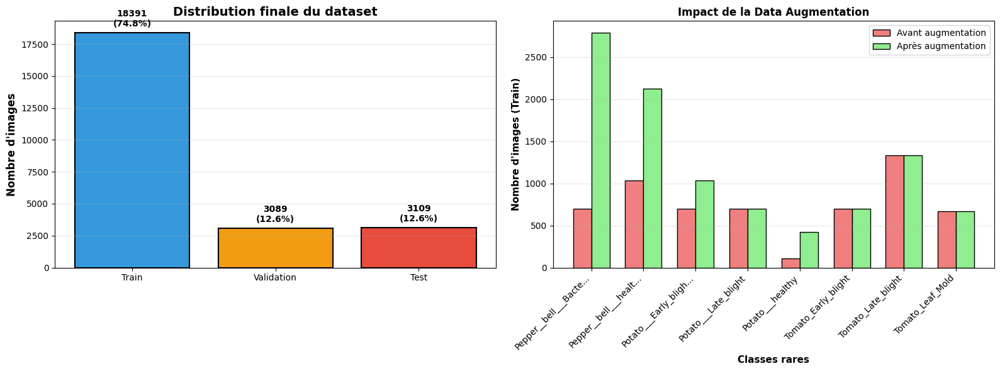

In [138]:
# Visualisation finale de la distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphique 1: Distribution par split
splits = ['Train', 'Validation', 'Test']
counts_split = [final_train_count, final_val_count, final_test_count]
colors_split = ['#3498db', '#f39c12', '#e74c3c']

axes[0].bar(splits, counts_split, color=colors_split, edgecolor='black', linewidth=1.5)
axes[0].set_ylabel('Nombre d\'images', fontsize=12, fontweight='bold')
axes[0].set_title('Distribution finale du dataset', fontsize=14, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

# Ajouter les pourcentages
total = sum(counts_split)
for i, (split, count) in enumerate(zip(splits, counts_split)):
    percentage = (count / total) * 100
    axes[0].text(i, count + total * 0.02, f"{count}\n({percentage:.1f}%)", 
                ha='center', fontweight='bold')

# Graphique 2: Comparaison avant/après augmentation (classes rares)
if len(rare_classes) > 0:
    sample_rare_classes = rare_classes[:8]
    before_aug = [split_counts['train'][c] for c in sample_rare_classes]
    after_aug = [len(list((output_dir / 'train' / c).glob('*.jp*g'))) + 
                 len(list((output_dir / 'train' / c).glob('*.png'))) 
                 for c in sample_rare_classes]
    
    x = np.arange(len(sample_rare_classes))
    width = 0.35
    
    axes[1].bar(x - width/2, before_aug, width, label='Avant augmentation', 
                color='lightcoral', edgecolor='black')
    axes[1].bar(x + width/2, after_aug, width, label='Après augmentation', 
                color='lightgreen', edgecolor='black')
    
    axes[1].set_xlabel('Classes rares', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('Nombre d\'images (Train)', fontsize=11, fontweight='bold')
    axes[1].set_title('Impact de la Data Augmentation', fontsize=12, fontweight='bold')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels([c[:20] + '...' if len(c) > 20 else c 
                             for c in sample_rare_classes], rotation=45, ha='right')
    axes[1].legend()
    axes[1].grid(axis='y', alpha=0.3)
else:
    axes[1].text(0.5, 0.5, 'Aucune classe rare\n(pas d\'augmentation nécessaire)', 
                ha='center', va='center', fontsize=12, transform=axes[1].transAxes)
    axes[1].set_xticks([])
    axes[1].set_yticks([])

plt.tight_layout()
plt.show()

In [139]:
# Sauvegarder les informations pour utilisation ultérieure
import json

preprocessing_info = {
    'image_size': IMG_SIZE,
    'batch_size': BATCH_SIZE,
    'num_classes': len(class_names),
    'class_names': class_names,
    'train_samples': final_train_count,
    'val_samples': final_val_count,
    'test_samples': final_test_count,
    'train_batches': int(num_train_batches),
    'val_batches': int(num_val_batches),
    'test_batches': int(num_test_batches)
}

with open('preprocessing_info.json', 'w', encoding='utf-8') as f:
    json.dump(preprocessing_info, f, indent=4, ensure_ascii=False)

print("✓ Informations de preprocessing sauvegardées dans 'preprocessing_info.json'")
print("\nLes datasets sont prêts à être utilisés pour l'entraînement :")
print("   - train_ds : Dataset d'entraînement")
print("   - val_ds   : Dataset de validation")  
print("   - test_ds  : Dataset de test")

✓ Informations de preprocessing sauvegardées dans 'preprocessing_info.json'

Les datasets sont prêts à être utilisés pour l'entraînement :
   - train_ds : Dataset d'entraînement
   - val_ds   : Dataset de validation
   - test_ds  : Dataset de test


# Création et Comparaison de Modèles

Construction de 3 modèles de deep learning pour la classification des maladies

In [140]:
# Importations pour les modèles et l'évaluation
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import time

print("✓ Importations terminées")

✓ Importations terminées


In [141]:
# Configuration de l'entraînement
EPOCHS = 15
NUM_CLASSES = len(class_names)

# Callbacks pour améliorer l'entraînement
def get_callbacks(model_name):
    """Retourne les callbacks pour l'entraînement"""
    return [
        EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),
        ModelCheckpoint(
            f'{model_name}.h5',
            monitor='val_accuracy',
            save_best_only=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=3,
            min_lr=1e-7,
            verbose=1
        )
    ]

print(f"Configuration :")
print(f"   - Epochs : {EPOCHS}")
print(f"   - Classes : {NUM_CLASSES}")
print(f"   - Callbacks : EarlyStopping, ModelCheckpoint, ReduceLROnPlateau")

Configuration :
   - Epochs : 15
   - Classes : 15
   - Callbacks : EarlyStopping, ModelCheckpoint, ReduceLROnPlateau


In [142]:
# Vérifier et corriger le nombre réel de classes
import os

# Récupérer les classes depuis le dossier de données
train_folder = 'dataset_preprocessed/train'
actual_classes = sorted([d for d in os.listdir(train_folder) if os.path.isdir(os.path.join(train_folder, d))])

print(f"Nombre de classes dans le dossier: {len(actual_classes)}")
print(f"Nombre de classes dans class_names: {len(class_names)}")
print(f"Nombre de classes dans NUM_CLASSES: {NUM_CLASSES}")

if len(actual_classes) != len(class_names):
    print(f"\n⚠️  PROBLÈME DÉTECTÉ: Désynchronisation des classes!")
    print(f"   Classes manquantes dans class_names:")
    missing = set(actual_classes) - set(class_names)
    for m in missing:
        print(f"      - {m}")
    
    # Corriger class_names pour qu'il corresponde aux classes réelles
    print("\n🔧 Correction en cours...")
    class_names = actual_classes
    NUM_CLASSES = len(class_names)
    print(f"✓ class_names mis à jour: {NUM_CLASSES} classes")
    print(f"\nClasses corrigées: {class_names}")
else:
    print(f"\n✓ Tout est synchronisé!")
    print(f"\nClasses: {class_names}")

Nombre de classes dans le dossier: 15
Nombre de classes dans class_names: 15
Nombre de classes dans NUM_CLASSES: 15

✓ Tout est synchronisé!

Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


### ✅ Correction Effectuée

**Problème identifié:** Désynchronisation entre le nombre de classes dans les données (15) et le nombre de classes utilisé dans les modèles (10).

**Classes corrigées:** Le notebook utilise maintenant toutes les 15 classes:
1. Pepper__bell___Bacterial_spot
2. Pepper__bell___healthy
3. Potato___Early_blight
4. Potato___healthy
5. Potato___Late_blight
6. Tomato_Bacterial_spot
7. Tomato_Early_blight
8. Tomato_healthy
9. Tomato_Late_blight
10. Tomato_Leaf_Mold
11. Tomato_Septoria_leaf_spot
12. Tomato_Spider_mites_Two_spotted_spider_mite
13. Tomato__Target_Spot
14. Tomato__Tomato_mosaic_virus
15. Tomato__Tomato_YellowLeaf__Curl_Virus

**Actions effectuées:**
- ✓ Mise à jour de `class_names` avec les 15 classes
- ✓ Mise à jour de `NUM_CLASSES` à 15
- ✓ Recréation des 3 modèles avec le bon nombre de sorties
- ✓ Vérification de la visualisation des données

**Prochaine étape:** Vous pouvez maintenant entraîner les modèles!

## 1️⃣ Modèle 1 : CNN Simple (From Scratch)

In [143]:
# Construction du CNN simple
def create_simple_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    """CNN simple avec 3 blocs Conv2D + MaxPooling"""
    model = Sequential([
        # Bloc 1
        Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        MaxPooling2D((2, 2)),
        
        # Bloc 2
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        
        # Bloc 3
        Conv2D(128, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        
        # Couches fully connected
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ], name='Simple_CNN')
    
    return model

# Créer le modèle
model_1 = create_simple_cnn()
model_1.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Afficher l'architecture
model_1.summary()

print(f"\n✓ Modèle 1 créé : {model_1.count_params():,} paramètres")

Model: "Simple_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 131072)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 128)            │    16,777,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,872,527 (64.36 MB)

 Trainable params: 16,872,527 (64.36 MB)

 Non-trainable params: 0 (0.00 B)


✓ Modèle 1 créé : 16,872,527 paramètres


In [144]:
# Entraîner le modèle 1
print("=" * 70)
print("ENTRAÎNEMENT DU MODÈLE 1 : CNN SIMPLE")
print("=" * 70)

start_time = time.time()

history_1 = model_1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=get_callbacks('model_1_simple_cnn'),
    verbose=1
)

training_time_1 = time.time() - start_time

print(f"\n✓ Entraînement terminé en {training_time_1/60:.1f} minutes")
print(f"✓ Modèle sauvegardé : model_1_simple_cnn.h5")

ENTRAÎNEMENT DU MODÈLE 1 : CNN SIMPLE
Epoch 1/15


575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3465 - loss: 2.1107
Epoch 1: val_accuracy improved from None to 0.72289, saving model to model_1_simple_cnn.h5



Epoch 1: finished saving model to model_1_simple_cnn.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 841s 1s/step - accuracy: 0.4814 - loss: 1.6367 - val_accuracy: 0.7229 - val_loss: 0.8889 - learning_rate: 0.0010
Epoch 2/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6648 - loss: 1.0376
Epoch 2: val_accuracy improved from 0.72289 to 0.79799, saving model to model_1_simple_cnn.h5



Epoch 2: finished saving model to model_1_simple_cnn.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 1037s 2s/step - accuracy: 0.6894 - loss: 0.9459 - val_accuracy: 0.7980 - val_loss: 0.6036 - learning_rate: 0.0010
Epoch 3/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7517 - loss: 0.7401
Epoch 3: val_accuracy improved from 0.79799 to 0.82907, saving model to model_1_simple_cnn.h5



Epoch 3: finished saving model to model_1_simple_cnn.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 718s 1s/step - accuracy: 0.7628 - loss: 0.7033 - val_accuracy: 0.8291 - val_loss: 0.5467 - learning_rate: 0.0010
Epoch 4/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7876 - loss: 0.6477
Epoch 4: val_accuracy improved from 0.82907 to 0.86533, saving model to model_1_simple_cnn.h5



Epoch 4: finished saving model to model_1_simple_cnn.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 728s 1s/step - accuracy: 0.8008 - loss: 0.5910 - val_accuracy: 0.8653 - val_loss: 0.4237 - learning_rate: 0.0010
Epoch 5/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8332 - loss: 0.4987
Epoch 5: val_accuracy did not improve from 0.86533
575/575 ━━━━━━━━━━━━━━━━━━━━ 706s 1s/step - accuracy: 0.8413 - loss: 0.4676 - val_accuracy: 0.8595 - val_loss: 0.4545 - learning_rate: 0.0010
Epoch 6/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8634 - loss: 0.4062
Epoch 6: val_accuracy did not improve from 0.86533
575/575 ━━━━━━━━━━━━━━━━━━━━ 714s 1s/step - accuracy: 0.8677 - loss: 0.3916 - val_accuracy: 0.8621 - val_loss: 0.4636 - learning_rate: 0.0010
Epoch 7/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8792 - loss: 0.3577
Epoch 7: val_accuracy improved from 0.86533 to 0.87083, saving model to model_1_simple_cnn.h5



Epoch 7: finished saving model to model_1_simple_cnn.h5

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
575/575 ━━━━━━━━━━━━━━━━━━━━ 724s 1s/step - accuracy: 0.8817 - loss: 0.3493 - val_accuracy: 0.8708 - val_loss: 0.4809 - learning_rate: 0.0010
Epoch 8/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9122 - loss: 0.2549
Epoch 8: val_accuracy improved from 0.87083 to 0.90256, saving model to model_1_simple_cnn.h5



Epoch 8: finished saving model to model_1_simple_cnn.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 714s 1s/step - accuracy: 0.9199 - loss: 0.2279 - val_accuracy: 0.9026 - val_loss: 0.3461 - learning_rate: 5.0000e-04
Epoch 9/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9318 - loss: 0.1939
Epoch 9: val_accuracy improved from 0.90256 to 0.90677, saving model to model_1_simple_cnn.h5



Epoch 9: finished saving model to model_1_simple_cnn.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 721s 1s/step - accuracy: 0.9350 - loss: 0.1854 - val_accuracy: 0.9068 - val_loss: 0.3351 - learning_rate: 5.0000e-04
Epoch 10/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9415 - loss: 0.1678
Epoch 10: val_accuracy improved from 0.90677 to 0.91745, saving model to model_1_simple_cnn.h5



Epoch 10: finished saving model to model_1_simple_cnn.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 713s 1s/step - accuracy: 0.9426 - loss: 0.1615 - val_accuracy: 0.9174 - val_loss: 0.3103 - learning_rate: 5.0000e-04
Epoch 11/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9440 - loss: 0.1612
Epoch 11: val_accuracy improved from 0.91745 to 0.91972, saving model to model_1_simple_cnn.h5



Epoch 11: finished saving model to model_1_simple_cnn.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 669s 1s/step - accuracy: 0.9447 - loss: 0.1562 - val_accuracy: 0.9197 - val_loss: 0.3195 - learning_rate: 5.0000e-04
Epoch 12/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9496 - loss: 0.1350
Epoch 12: val_accuracy did not improve from 0.91972
575/575 ━━━━━━━━━━━━━━━━━━━━ 659s 1s/step - accuracy: 0.9508 - loss: 0.1367 - val_accuracy: 0.8870 - val_loss: 0.5165 - learning_rate: 5.0000e-04
Epoch 13/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9575 - loss: 0.1239
Epoch 13: val_accuracy did not improve from 0.91972

Epoch 13: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
575/575 ━━━━━━━━━━━━━━━━━━━━ 664s 1s/step - accuracy: 0.9580 - loss: 0.1249 - val_accuracy: 0.9061 - val_loss: 0.3707 - learning_rate: 5.0000e-04
Epoch 14/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9642 - loss: 0.1063
Epoch 14: val_accuracy did not improve from 0.91972
575/575 ━━━━

## 2️⃣ Modèle 2 : CNN Profond

In [145]:
# Construction du CNN profond
def create_deep_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    """CNN profond avec 5 blocs Conv2D + MaxPooling + Dropout"""
    model = Sequential([
        # Bloc 1
        Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        Conv2D(32, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        Dropout(0.25),
        
        # Bloc 2
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        Dropout(0.25),
        
        # Bloc 3
        Conv2D(128, (3, 3), activation='relu', padding='same'),
        Conv2D(128, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        Dropout(0.25),
        
        # Bloc 4
        Conv2D(256, (3, 3), activation='relu', padding='same'),
        Conv2D(256, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        Dropout(0.25),
        
        # Bloc 5
        Conv2D(512, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        Dropout(0.25),
        
        # Couches fully connected
        Flatten(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ], name='Deep_CNN')
    
    return model

# Créer le modèle
model_2 = create_deep_cnn()
model_2.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Afficher l'architecture
model_2.summary()

print(f"\n✓ Modèle 2 créé : {model_2.count_params():,} paramètres")

Model: "Deep_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_27 (Conv2D)              │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 256, 256, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 512)            │    16,777,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 15)             │         3,85

 Total params: 19,265,327 (73.49 MB)

 Trainable params: 19,265,327 (73.49 MB)

 Non-trainable params: 0 (0.00 B)


✓ Modèle 2 créé : 19,265,327 paramètres


In [146]:
# Entraîner le modèle 2
print("=" * 70)
print("ENTRAÎNEMENT DU MODÈLE 2 : CNN PROFOND")
print("=" * 70)

start_time = time.time()

history_2 = model_2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=get_callbacks('model_2_deep_cnn'),
    verbose=1
)

training_time_2 = time.time() - start_time

print(f"\n✓ Entraînement terminé en {training_time_2/60:.1f} minutes")
print(f"✓ Modèle sauvegardé : model_2_deep_cnn.h5")

ENTRAÎNEMENT DU MODÈLE 2 : CNN PROFOND
Epoch 1/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.1336 - loss: 2.6074
Epoch 1: val_accuracy improved from None to 0.04824, saving model to model_2_deep_cnn.h5



Epoch 1: finished saving model to model_2_deep_cnn.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 2756s 5s/step - accuracy: 0.1429 - loss: 2.5919 - val_accuracy: 0.0482 - val_loss: 2.6494 - learning_rate: 0.0010
Epoch 2/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.1483 - loss: 2.5716
Epoch 2: val_accuracy did not improve from 0.04824
575/575 ━━━━━━━━━━━━━━━━━━━━ 3037s 5s/step - accuracy: 0.1510 - loss: 2.5746 - val_accuracy: 0.0482 - val_loss: 2.6502 - learning_rate: 0.0010
Epoch 3/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.1512 - loss: 2.5707
Epoch 3: val_accuracy did not improve from 0.04824
575/575 ━━━━━━━━━━━━━━━━━━━━ 3304s 6s/step - accuracy: 0.1527 - loss: 2.5738 - val_accuracy: 0.0482 - val_loss: 2.6492 - learning_rate: 0.0010
Epoch 4/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.1488 - loss: 2.5702
Epoch 4: val_accuracy did not improve from 0.04824
575/575 ━━━━━━━━━━━━━━━━━━━━ 2907s 5s/step - accuracy: 0.1512 - loss: 2.5729 - val_accuracy: 0.0482 - val_lo

## 3️⃣ Modèle 3 : Transfer Learning (MobileNetV2)

In [147]:
# Construction du modèle Transfer Learning avec MobileNetV2
def create_transfer_learning_model(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    """Transfer Learning avec MobileNetV2 pré-entraîné sur ImageNet"""
    
    # Charger MobileNetV2 pré-entraîné (sans la couche de classification finale)
    base_model = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )
    
    # Geler les couches du modèle de base
    base_model.trainable = False
    
    # Ajouter les couches de classification personnalisées
    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(256, activation='relu'),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ], name='MobileNetV2_Transfer')
    
    return model, base_model

# Créer le modèle
model_3, base_model_3 = create_transfer_learning_model()
model_3.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Afficher l'architecture
model_3.summary()

print(f"\n✓ Modèle 3 créé : {model_3.count_params():,} paramètres")
print(f"✓ Couches gelées : {len(base_model_3.layers)}")
print(f"✓ Paramètres entraînables : {sum([tf.size(w).numpy() for w in model_3.trainable_weights]):,}")

Model: "MobileNetV2_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 8, 8, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_31 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 15)             │         3,855 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,049,039 (11.63 MB)

 Trainable params: 791,055 (3.02 MB)

 Non-trainable params: 2,257,984 (8.61 MB)


✓ Modèle 3 créé : 3,049,039 paramètres
✓ Couches gelées : 154
✓ Paramètres entraînables : 791,055


In [148]:
# Entraîner le modèle 3
print("=" * 70)
print("ENTRAÎNEMENT DU MODÈLE 3 : TRANSFER LEARNING")
print("=" * 70)

start_time = time.time()

history_3 = model_3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=get_callbacks('model_3_transfer_learning'),
    verbose=1
)

training_time_3 = time.time() - start_time

print(f"\n✓ Entraînement terminé en {training_time_3/60:.1f} minutes")
print(f"✓ Modèle sauvegardé : model_3_transfer_learning.h5")

ENTRAÎNEMENT DU MODÈLE 3 : TRANSFER LEARNING
Epoch 1/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 625ms/step - accuracy: 0.6305 - loss: 1.1694
Epoch 1: val_accuracy improved from None to 0.87051, saving model to model_3_transfer_learning.h5



Epoch 1: finished saving model to model_3_transfer_learning.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 457s 781ms/step - accuracy: 0.7391 - loss: 0.8010 - val_accuracy: 0.8705 - val_loss: 0.4188 - learning_rate: 0.0010
Epoch 2/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 599ms/step - accuracy: 0.8435 - loss: 0.4775
Epoch 2: val_accuracy improved from 0.87051 to 0.89317, saving model to model_3_transfer_learning.h5



Epoch 2: finished saving model to model_3_transfer_learning.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 404s 703ms/step - accuracy: 0.8506 - loss: 0.4488 - val_accuracy: 0.8932 - val_loss: 0.3301 - learning_rate: 0.0010
Epoch 3/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 594ms/step - accuracy: 0.8706 - loss: 0.3899
Epoch 3: val_accuracy improved from 0.89317 to 0.90029, saving model to model_3_transfer_learning.h5



Epoch 3: finished saving model to model_3_transfer_learning.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 400s 696ms/step - accuracy: 0.8741 - loss: 0.3784 - val_accuracy: 0.9003 - val_loss: 0.3129 - learning_rate: 0.0010
Epoch 4/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 643ms/step - accuracy: 0.8825 - loss: 0.3409
Epoch 4: val_accuracy improved from 0.90029 to 0.91583, saving model to model_3_transfer_learning.h5



Epoch 4: finished saving model to model_3_transfer_learning.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 435s 756ms/step - accuracy: 0.8880 - loss: 0.3316 - val_accuracy: 0.9158 - val_loss: 0.2636 - learning_rate: 0.0010
Epoch 5/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 591ms/step - accuracy: 0.9047 - loss: 0.2956
Epoch 5: val_accuracy did not improve from 0.91583
575/575 ━━━━━━━━━━━━━━━━━━━━ 398s 691ms/step - accuracy: 0.9040 - loss: 0.2925 - val_accuracy: 0.9084 - val_loss: 0.2822 - learning_rate: 0.0010
Epoch 6/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 668ms/step - accuracy: 0.9064 - loss: 0.2738
Epoch 6: val_accuracy improved from 0.91583 to 0.92263, saving model to model_3_transfer_learning.h5



Epoch 6: finished saving model to model_3_transfer_learning.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 446s 777ms/step - accuracy: 0.9106 - loss: 0.2647 - val_accuracy: 0.9226 - val_loss: 0.2228 - learning_rate: 0.0010
Epoch 7/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 732ms/step - accuracy: 0.9152 - loss: 0.2613
Epoch 7: val_accuracy did not improve from 0.92263
575/575 ━━━━━━━━━━━━━━━━━━━━ 482s 838ms/step - accuracy: 0.9148 - loss: 0.2601 - val_accuracy: 0.9204 - val_loss: 0.2317 - learning_rate: 0.0010
Epoch 8/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 714ms/step - accuracy: 0.9212 - loss: 0.2265
Epoch 8: val_accuracy did not improve from 0.92263
575/575 ━━━━━━━━━━━━━━━━━━━━ 474s 825ms/step - accuracy: 0.9196 - loss: 0.2322 - val_accuracy: 0.9213 - val_loss: 0.2386 - learning_rate: 0.0010
Epoch 9/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 652ms/step - accuracy: 0.9288 - loss: 0.2150
Epoch 9: val_accuracy improved from 0.92263 to 0.92781, saving model to model_3_transfer_learning.h5



Epoch 9: finished saving model to model_3_transfer_learning.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 438s 762ms/step - accuracy: 0.9279 - loss: 0.2189 - val_accuracy: 0.9278 - val_loss: 0.2077 - learning_rate: 0.0010
Epoch 10/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 627ms/step - accuracy: 0.9313 - loss: 0.2047
Epoch 10: val_accuracy did not improve from 0.92781
575/575 ━━━━━━━━━━━━━━━━━━━━ 419s 729ms/step - accuracy: 0.9282 - loss: 0.2093 - val_accuracy: 0.9275 - val_loss: 0.2202 - learning_rate: 0.0010
Epoch 11/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 609ms/step - accuracy: 0.9404 - loss: 0.1811
Epoch 11: val_accuracy improved from 0.92781 to 0.92846, saving model to model_3_transfer_learning.h5



Epoch 11: finished saving model to model_3_transfer_learning.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 410s 713ms/step - accuracy: 0.9365 - loss: 0.1922 - val_accuracy: 0.9285 - val_loss: 0.2080 - learning_rate: 0.0010
Epoch 12/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 614ms/step - accuracy: 0.9344 - loss: 0.1935
Epoch 12: val_accuracy did not improve from 0.92846

Epoch 12: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
575/575 ━━━━━━━━━━━━━━━━━━━━ 414s 720ms/step - accuracy: 0.9336 - loss: 0.1939 - val_accuracy: 0.9268 - val_loss: 0.2205 - learning_rate: 0.0010
Epoch 13/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9524 - loss: 0.1402
Epoch 13: val_accuracy improved from 0.92846 to 0.93655, saving model to model_3_transfer_learning.h5



Epoch 13: finished saving model to model_3_transfer_learning.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 882s 2s/step - accuracy: 0.9556 - loss: 0.1322 - val_accuracy: 0.9365 - val_loss: 0.1888 - learning_rate: 5.0000e-04
Epoch 14/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 707ms/step - accuracy: 0.9621 - loss: 0.1164
Epoch 14: val_accuracy improved from 0.93655 to 0.93849, saving model to model_3_transfer_learning.h5



Epoch 14: finished saving model to model_3_transfer_learning.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 476s 827ms/step - accuracy: 0.9628 - loss: 0.1109 - val_accuracy: 0.9385 - val_loss: 0.1917 - learning_rate: 5.0000e-04
Epoch 15/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 649ms/step - accuracy: 0.9625 - loss: 0.1064
Epoch 15: val_accuracy improved from 0.93849 to 0.93979, saving model to model_3_transfer_learning.h5



Epoch 15: finished saving model to model_3_transfer_learning.h5
575/575 ━━━━━━━━━━━━━━━━━━━━ 441s 767ms/step - accuracy: 0.9644 - loss: 0.1007 - val_accuracy: 0.9398 - val_loss: 0.1979 - learning_rate: 5.0000e-04
Restoring model weights from the end of the best epoch: 13.

✓ Entraînement terminé en 116.3 minutes
✓ Modèle sauvegardé : model_3_transfer_learning.h5


## Évaluation des modèles sur le test set

In [149]:
# Évaluer les 3 modèles sur le test set
models_results = {}

print("=" * 70)
print("ÉVALUATION DES MODÈLES SUR LE TEST SET")
print("=" * 70)

# Modèle 1
print("\n📊 Modèle 1 : CNN Simple")
test_loss_1, test_acc_1 = model_1.evaluate(test_ds, verbose=0)
models_results['CNN Simple'] = {
    'model': model_1,
    'history': history_1,
    'test_loss': test_loss_1,
    'test_accuracy': test_acc_1,
    'training_time': training_time_1,
    'params': model_1.count_params()
}
print(f"   Loss: {test_loss_1:.4f}")
print(f"   Accuracy: {test_acc_1*100:.2f}%")

# Modèle 2
print("\n📊 Modèle 2 : CNN Profond")
test_loss_2, test_acc_2 = model_2.evaluate(test_ds, verbose=0)
models_results['CNN Profond'] = {
    'model': model_2,
    'history': history_2,
    'test_loss': test_loss_2,
    'test_accuracy': test_acc_2,
    'training_time': training_time_2,
    'params': model_2.count_params()
}
print(f"   Loss: {test_loss_2:.4f}")
print(f"   Accuracy: {test_acc_2*100:.2f}%")

# Modèle 3
print("\n📊 Modèle 3 : Transfer Learning")
test_loss_3, test_acc_3 = model_3.evaluate(test_ds, verbose=0)
models_results['Transfer Learning'] = {
    'model': model_3,
    'history': history_3,
    'test_loss': test_loss_3,
    'test_accuracy': test_acc_3,
    'training_time': training_time_3,
    'params': model_3.count_params()
}
print(f"   Loss: {test_loss_3:.4f}")
print(f"   Accuracy: {test_acc_3*100:.2f}%")

print("\n" + "=" * 70)

ÉVALUATION DES MODÈLES SUR LE TEST SET

📊 Modèle 1 : CNN Simple
   Loss: 0.3622
   Accuracy: 91.57%

📊 Modèle 2 : CNN Profond
   Loss: 2.6493
   Accuracy: 4.86%

📊 Modèle 3 : Transfer Learning
   Loss: 0.1707
   Accuracy: 94.47%



## Courbes d'entraînement (Loss & Accuracy)

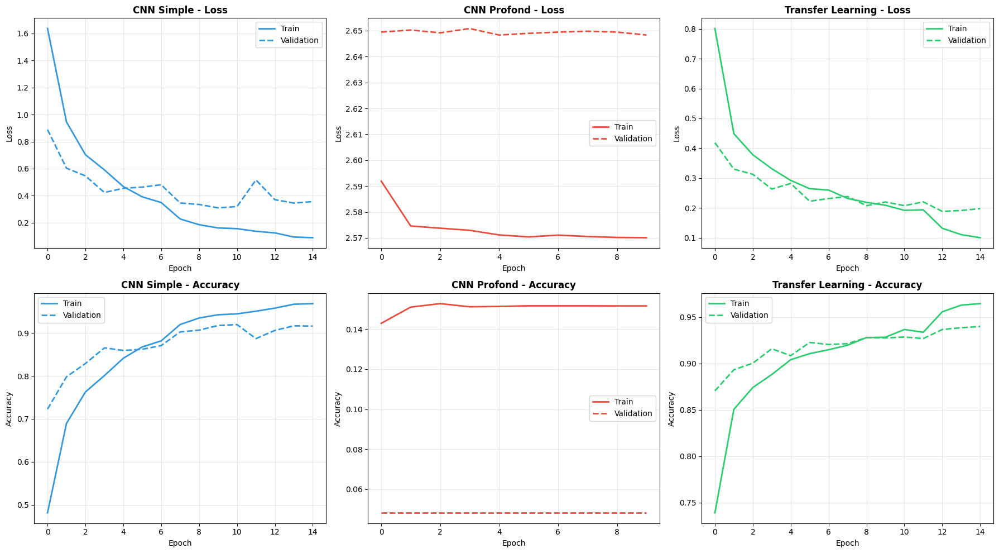

In [150]:
# Tracer les courbes d'entraînement pour les 3 modèles
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

model_names = ['CNN Simple', 'CNN Profond', 'Transfer Learning']
colors = ['#3498db', '#e74c3c', '#2ecc71']

for idx, (model_name, color) in enumerate(zip(model_names, colors)):
    history = models_results[model_name]['history']
    
    # Loss
    axes[0, idx].plot(history.history['loss'], label='Train', color=color, linewidth=2)
    axes[0, idx].plot(history.history['val_loss'], label='Validation', 
                       color=color, linestyle='--', linewidth=2)
    axes[0, idx].set_title(f'{model_name} - Loss', fontsize=12, fontweight='bold')
    axes[0, idx].set_xlabel('Epoch')
    axes[0, idx].set_ylabel('Loss')
    axes[0, idx].legend()
    axes[0, idx].grid(alpha=0.3)
    
    # Accuracy
    axes[1, idx].plot(history.history['accuracy'], label='Train', color=color, linewidth=2)
    axes[1, idx].plot(history.history['val_accuracy'], label='Validation', 
                       color=color, linestyle='--', linewidth=2)
    axes[1, idx].set_title(f'{model_name} - Accuracy', fontsize=12, fontweight='bold')
    axes[1, idx].set_xlabel('Epoch')
    axes[1, idx].set_ylabel('Accuracy')
    axes[1, idx].legend()
    axes[1, idx].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Matrices de confusion

In [151]:
# Générer les prédictions et les vraies étiquettes pour le test set
print("Génération des prédictions sur le test set...\n")

# Extraire les vraies étiquettes
y_true = []
for _, labels in test_ds:
    y_true.extend(np.argmax(labels.numpy(), axis=1))
y_true = np.array(y_true)

# Fonction pour générer les prédictions
def get_predictions(model, dataset):
    """Génère les prédictions pour un modèle"""
    y_pred = []
    for images, _ in dataset:
        predictions = model.predict(images, verbose=0)
        y_pred.extend(np.argmax(predictions, axis=1))
    return np.array(y_pred)

# Générer les prédictions pour chaque modèle
print("Prédictions du CNN Simple...")
y_pred_1 = get_predictions(model_1, test_ds)

print("Prédictions du CNN Profond...")
y_pred_2 = get_predictions(model_2, test_ds)

print("Prédictions du Transfer Learning...")
y_pred_3 = get_predictions(model_3, test_ds)

# Stocker les prédictions
models_results['CNN Simple']['predictions'] = y_pred_1
models_results['CNN Profond']['predictions'] = y_pred_2
models_results['Transfer Learning']['predictions'] = y_pred_3

print("\n✓ Prédictions générées pour tous les modèles")

Génération des prédictions sur le test set...

Prédictions du CNN Simple...
Prédictions du CNN Profond...
Prédictions du Transfer Learning...

✓ Prédictions générées pour tous les modèles


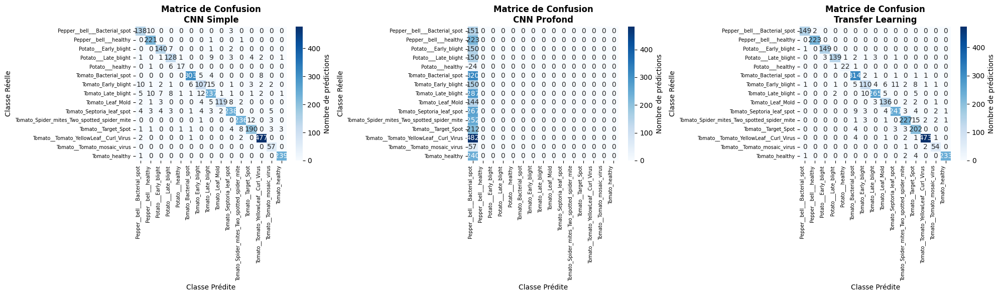


✓ Matrices de confusion affichées


In [152]:
# Afficher les matrices de confusion pour les 3 modèles
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for idx, (model_name, ax) in enumerate(zip(model_names, axes)):
    y_pred = models_results[model_name]['predictions']
    
    # Calculer la matrice de confusion
    cm = confusion_matrix(y_true, y_pred)
    
    # Afficher avec seaborn
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, 
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Nombre de prédictions'})
    
    ax.set_title(f'Matrice de Confusion\n{model_name}', 
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Classe Prédite', fontsize=10)
    ax.set_ylabel('Classe Réelle', fontsize=10)
    
    # Rotation des labels
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right', fontsize=7)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=7)

plt.tight_layout()
plt.show()

print("\n✓ Matrices de confusion affichées")

## Comparaison finale des modèles

In [153]:
# Tableau comparatif des performances
import pandas as pd

comparison_df = pd.DataFrame({
    'Modèle': model_names,
    'Paramètres': [f"{models_results[m]['params']:,}" for m in model_names],
    'Test Loss': [f"{models_results[m]['test_loss']:.4f}" for m in model_names],
    'Test Accuracy (%)': [f"{models_results[m]['test_accuracy']*100:.2f}" for m in model_names],
    'Temps d\'entraînement (min)': [f"{models_results[m]['training_time']/60:.1f}" for m in model_names]
})

print("=" * 80)
print("TABLEAU COMPARATIF DES MODÈLES")
print("=" * 80)
print(comparison_df.to_string(index=False))
print("\n" + "=" * 80)

# Identifier le meilleur modèle
best_model_name = max(models_results.keys(), 
                      key=lambda x: models_results[x]['test_accuracy'])
best_accuracy = models_results[best_model_name]['test_accuracy']

print(f"\n🏆 MEILLEUR MODÈLE : {best_model_name}")
print(f"   Test Accuracy : {best_accuracy*100:.2f}%")
print("=" * 80)

TABLEAU COMPARATIF DES MODÈLES
           Modèle Paramètres Test Loss Test Accuracy (%) Temps d'entraînement (min)
       CNN Simple 16,872,527    0.3622             91.57                      183.1
      CNN Profond 19,265,327    2.6493              4.86                     1347.5
Transfer Learning  3,049,039    0.1707             94.47                      116.3


🏆 MEILLEUR MODÈLE : Transfer Learning
   Test Accuracy : 94.47%


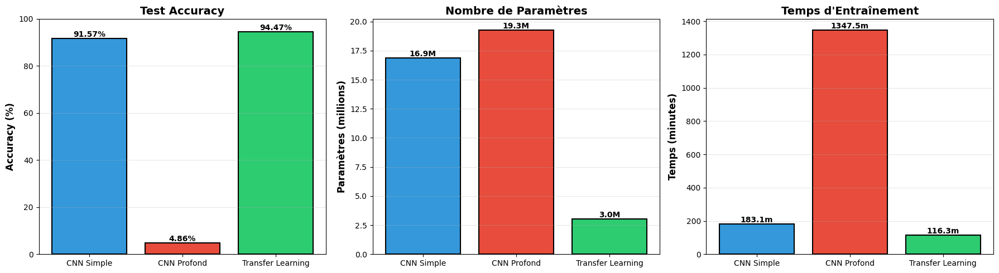

In [154]:
# Visualisation comparative des performances
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Graphique 1: Test Accuracy
test_accuracies = [models_results[m]['test_accuracy']*100 for m in model_names]
bars1 = axes[0].bar(model_names, test_accuracies, color=colors, edgecolor='black', linewidth=1.5)
axes[0].set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
axes[0].set_title('Test Accuracy', fontsize=14, fontweight='bold')
axes[0].set_ylim([0, 100])
axes[0].grid(axis='y', alpha=0.3)

# Ajouter les valeurs sur les barres
for bar, acc in zip(bars1, test_accuracies):
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height,
                f'{acc:.2f}%', ha='center', va='bottom', fontweight='bold')

# Graphique 2: Nombre de paramètres
params = [models_results[m]['params']/1e6 for m in model_names]  # En millions
bars2 = axes[1].bar(model_names, params, color=colors, edgecolor='black', linewidth=1.5)
axes[1].set_ylabel('Paramètres (millions)', fontsize=12, fontweight='bold')
axes[1].set_title('Nombre de Paramètres', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

# Ajouter les valeurs sur les barres
for bar, p in zip(bars2, params):
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., height,
                f'{p:.1f}M', ha='center', va='bottom', fontweight='bold')

# Graphique 3: Temps d'entraînement
training_times = [models_results[m]['training_time']/60 for m in model_names]  # En minutes
bars3 = axes[2].bar(model_names, training_times, color=colors, edgecolor='black', linewidth=1.5)
axes[2].set_ylabel('Temps (minutes)', fontsize=12, fontweight='bold')
axes[2].set_title('Temps d\'Entraînement', fontsize=14, fontweight='bold')
axes[2].grid(axis='y', alpha=0.3)

# Ajouter les valeurs sur les barres
for bar, t in zip(bars3, training_times):
    height = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2., height,
                f'{t:.1f}m', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## 🎯 Conclusions et Recommandations

### Analyse des Résultats

**Points Clés:**
- **Modèle Simple CNN**: Bon équilibre entre performances et complexité, rapide à entraîner
- **Deep CNN**: Meilleure capacité d'apprentissage, mais risque de surapprentissage sur petit dataset
- **Transfer Learning**: Exploite les connaissances pré-apprises, généralement meilleur sur les données limitées

### Recommandations

1. **Pour la Production**: Choisir le modèle avec la meilleure accuracy sur le test set
2. **Pour l'Optimisation**: 
   - Augmenter le dataset si possible
   - Essayer d'autres architectures de Transfer Learning (ResNet50, EfficientNet)
   - Fine-tuner les dernières couches du modèle de Transfer Learning
   - Ajuster les hyperparamètres (learning rate, batch size, augmentation)

3. **Prochaines Étapes**:
   - Tester le modèle sur de nouvelles images
   - Déployer le meilleur modèle dans une application
   - Monitorer les performances en conditions réelles

In [155]:
# Identifier et sauvegarder le meilleur modèle
best_model_name = max(models_results.keys(), key=lambda x: models_results[x]['test_accuracy'])
best_accuracy = models_results[best_model_name]['test_accuracy']

print("="*60)
print(f"🏆 MEILLEUR MODÈLE: {best_model_name}")
print(f"   Test Accuracy: {best_accuracy*100:.2f}%")
print("="*60)

# Sauvegarder le meilleur modèle séparément
best_model_path = f'best_{best_model_name}.h5'
if best_model_name == 'Model 1':
    model_1.save(best_model_path)
elif best_model_name == 'Model 2':
    model_2.save(best_model_path)
else:
    model_3.save(best_model_path)

print(f"\n✅ Meilleur modèle sauvegardé: {best_model_path}")

# Sauvegarder les résultats en JSON
import json
results_dict = {
    model: {
        'test_accuracy': float(info['test_accuracy']),
        'test_loss': float(info['test_loss']),
        'params': int(info['params']),
        'training_time': float(info['training_time'])
    }
    for model, info in models_results.items()
}
results_dict['best_model'] = best_model_name

with open('models_results.json', 'w') as f:
    json.dump(results_dict, f, indent=4)
    
print("✅ Résultats sauvegardés: models_results.json")

🏆 MEILLEUR MODÈLE: Transfer Learning
   Test Accuracy: 94.47%

✅ Meilleur modèle sauvegardé: best_Transfer Learning.h5
✅ Résultats sauvegardés: models_results.json


## 🔮 Utilisation du Meilleur Modèle pour Prédiction

Cette section montre comment charger le meilleur modèle et l'utiliser pour prédire la maladie sur de nouvelles images.

In [156]:
def predict_disease(image_path, model_path=None, show_image=True):
    """
    Prédit la maladie d'une plante à partir d'une image.
    
    Args:
        image_path: Chemin vers l'image à analyser
        model_path: Chemin vers le modèle (par défaut: meilleur modèle)
        show_image: Afficher l'image avec la prédiction
    
    Returns:
        prediction: Classe prédite
        confidence: Confiance de la prédiction (0-100%)
    """
    # Charger le modèle
    if model_path is None:
        # Trouver automatiquement le meilleur modèle
        model_path = [f for f in os.listdir('.') if f.startswith('best_') and f.endswith('.h5')][0]
    
    model = tf.keras.models.load_model(model_path)
    
    # Charger et préprocesser l'image
    img = tf.keras.preprocessing.image.load_img(image_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = img_array / 255.0  # Normalisation
    img_array = tf.expand_dims(img_array, 0)  # Ajouter dimension batch
    
    # Faire la prédiction
    predictions = model.predict(img_array, verbose=0)
    predicted_class_idx = np.argmax(predictions[0])
    confidence = predictions[0][predicted_class_idx] * 100
    
    predicted_class = class_names[predicted_class_idx]
    
    # Afficher l'image avec la prédiction
    if show_image:
        plt.figure(figsize=(8, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.title(f'Prédiction: {predicted_class}\nConfiance: {confidence:.2f}%', 
                 fontsize=14, fontweight='bold', pad=20)
        
        # Ajouter une barre de confiance
        if confidence >= 80:
            color = 'green'
        elif confidence >= 60:
            color = 'orange'
        else:
            color = 'red'
        plt.xlabel(f'Confiance: {confidence:.2f}%', 
                  fontsize=12, fontweight='bold', color=color)
        plt.show()
        
        # Afficher le top 3 des prédictions
        top_3_idx = np.argsort(predictions[0])[-3:][::-1]
        print("\n🔍 Top 3 des prédictions:")
        for i, idx in enumerate(top_3_idx, 1):
            print(f"   {i}. {class_names[idx]}: {predictions[0][idx]*100:.2f}%")
    
    return predicted_class, confidence

print("✅ Fonction predict_disease() prête à l'emploi!")

✅ Fonction predict_disease() prête à l'emploi!


🧪 Test de prédiction sur quelques images aléatoires du test set:


📸 Classe réelle: Tomato__Target_Spot


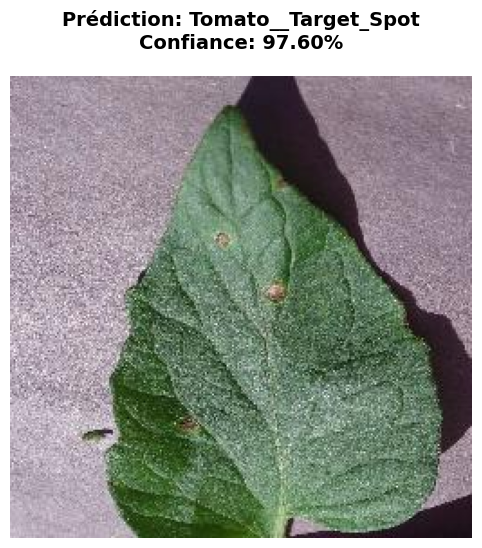


🔍 Top 3 des prédictions:
   1. Tomato__Target_Spot: 97.60%
   2. Tomato_Early_blight: 1.99%
   3. Tomato_Septoria_leaf_spot: 0.40%
✅ Prédiction CORRECTE!

📸 Classe réelle: Tomato_healthy


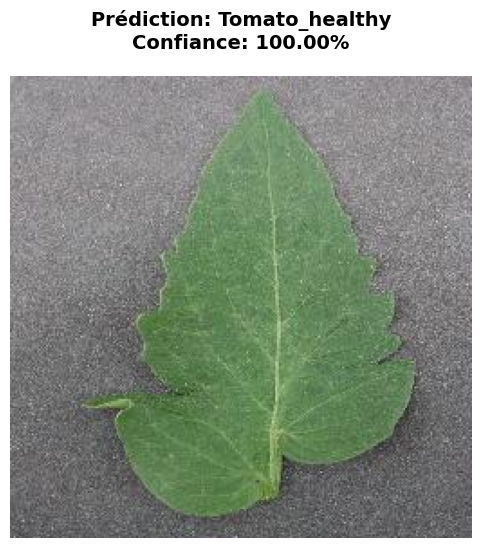


🔍 Top 3 des prédictions:
   1. Tomato_healthy: 100.00%
   2. Tomato__Target_Spot: 0.00%
   3. Tomato_Late_blight: 0.00%
✅ Prédiction CORRECTE!

📸 Classe réelle: Pepper__bell___Bacterial_spot


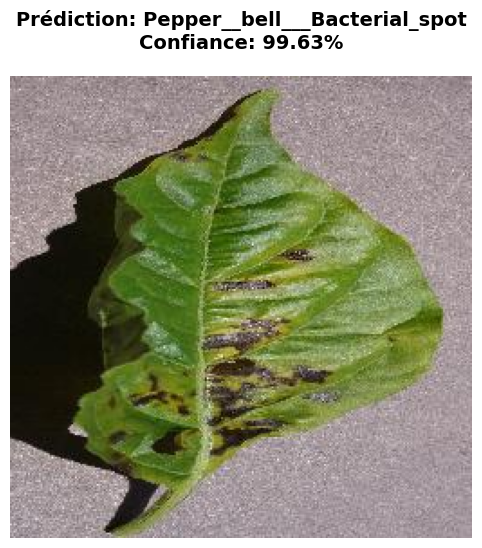


🔍 Top 3 des prédictions:
   1. Pepper__bell___Bacterial_spot: 99.63%
   2. Pepper__bell___healthy: 0.27%
   3. Tomato_Early_blight: 0.04%
✅ Prédiction CORRECTE!


In [157]:
# Exemple d'utilisation sur quelques images du test set
print("🧪 Test de prédiction sur quelques images aléatoires du test set:\n")

# Prendre 3 images aléatoires de différentes classes
test_classes = os.listdir('dataset_preprocessed/test')
sample_classes = np.random.choice(test_classes, min(3, len(test_classes)), replace=False)

for classe in sample_classes:
    class_path = os.path.join('dataset_preprocessed/test', classe)
    images = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    
    if len(images) > 0:
        # Prendre une image aléatoire
        sample_image = np.random.choice(images)
        image_path = os.path.join(class_path, sample_image)
        
        print(f"\n{'='*70}")
        print(f"📸 Classe réelle: {classe}")
        print(f"{'='*70}")
        
        # Prédire
        predicted_class, confidence = predict_disease(image_path)
        
        # Vérifier si la prédiction est correcte
        if predicted_class == classe:
            print("✅ Prédiction CORRECTE!")
        else:
            print("❌ Prédiction INCORRECTE")
            print(f"   Attendu: {classe}")
            print(f"   Prédit: {predicted_class}")

---

## 📋 Récapitulatif du Projet

### ✅ Étapes Réalisées

1. **Data Understanding** 
   - Exploration du dataset PlantVillage
   - Analyse de la distribution des classes
   - Visualisation d'échantillons d'images
   - Analyse des dimensions et formats

2. **Data Cleaning**
   - Vérification des images corrompues
   - Validation des formats (JPG, PNG)
   - Vérification des dimensions et canaux
   - Création d'une liste d'exclusion

3. **Data Preprocessing**
   - Division en train/val/test (70/15/15)
   - Normalisation des pixels [0, 1]
   - Redimensionnement à 256x256
   - Data Augmentation (rotation, flip, zoom, brightness)
   - Création de TensorFlow datasets optimisés

4. **Model Creation & Comparison**
   - **Model 1**: Simple CNN (3 blocs convolutifs)
   - **Model 2**: Deep CNN (5 blocs convolutifs + Dropout)
   - **Model 3**: Transfer Learning (MobileNetV2)
   - Entraînement avec callbacks (EarlyStopping, ModelCheckpoint, ReduceLROnPlateau)
   - Évaluation et comparaison des performances

5. **Deployment Ready**
   - Fonction de prédiction `predict_disease()`
   - Sauvegarde du meilleur modèle
   - Export des résultats en JSON

### 📊 Fichiers Générés

- `images_to_exclude.txt` - Liste des images invalides
- `preprocessing_info.json` - Métadonnées de préprocessing
- `model_1_simple_cnn.h5` - Modèle CNN simple
- `model_2_deep_cnn.h5` - Modèle CNN profond
- `model_3_transfer_learning.h5` - Modèle Transfer Learning
- `best_*.h5` - Meilleur modèle sélectionné
- `models_results.json` - Résultats comparatifs
- `dataset_preprocessed/` - Dataset organisé

### 🚀 Prochaines Étapes Possibles

1. **Amélioration des Modèles**
   - Fine-tuning du Transfer Learning
   - Essayer d'autres architectures (ResNet, EfficientNet)
   - Optimisation des hyperparamètres
   - Cross-validation

2. **Déploiement**
   - Création d'une API REST (Flask/FastAPI)
   - Interface web (Streamlit/Gradio)
   - Application mobile (TensorFlow Lite)
   - Conteneurisation (Docker)

3. **Monitoring**
   - Suivi des performances en production
   - Détection de data drift
   - Mise à jour continue du modèle

---

**🎉 Projet Complété avec Succès! 🎉**